# Solar PV Generation Forecasting in NSW: Data, Models and Evaluation
**MDS650 Capstone Project**

This notebook loads, cleans and aligns two primary data sources:

- `renewables_ninja_*.csv`: hourly MERRA-2 weather for eight NSW locations from September 2020 to 2025.
- `aemo_dispatchregionsum_nsw1.csv`: five-minute AEMO NSW1 dispatch-region observations from September 2020 to 2025.

**Forecast target:** `SS_SOLAR_CLEAREDMW_mean`, the hourly mean of NSW semi-scheduled solar cleared generation in MW. It is a market-dispatch quantity, not unconstrained physical PV production or total rooftop PV output.

**Research question:** To what extent do scale-normalised AEMO five-minute intra-hour variability features improve short-term solar PV forecast skill after controlling for ordinary hourly generation history in New South Wales?

**Controlled feature design:** Four information sets form a 2 x 2 ablation: weather only; weather plus hourly generation history; weather plus scale-normalised intra-hour variability; and weather plus both AEMO components. Every learned procedure evaluates the complete factorial design, so the controlled intra-hour contrast is estimated under the same information sets for XGBoost and all neural models.

| Source | Role | Used by the models? |
|---|---|---|
| Renewables.ninja weather | Meteorological predictors averaged across eight NSW sites | Yes |
| Renewables.ninja simulated PV output | External model output | No |
| AEMO semi-scheduled solar cleared generation | Forecast target and completed-hour history | Yes |
| AEMO coefficient of variation and relative range | Scale-normalised five-minute variability from completed hours | Yes |
| Future target observations | Information unavailable at the forecast origin | No |

**Models:** XGBoost, a unidirectional LSTM, an unconstrained CNN-BiLSTM and a matched physics-guided CNN-BiLSTM predict 1, 3, 6 and 24 completed hourly intervals ahead. Headline neural forecasts average five seed-specific predictions; XGBoost is a single fitted model. The matched CNN-BiLSTM pair differs only in the physical loss penalties, which isolates their predictive contribution under the tested training procedure. Comparisons with the simpler LSTM remain procedure-level. A validation-weighted ensemble is secondary.

**Chronology:** Training covers September 2020–2023, validation covers 2024 and the held-out test covers 2025. Scaling, tuning, early stopping and ensemble weighting use no test data. AEMO hourly rows carry the left-edge label of a completed interval. The issue time is one hour after the last input label; horizon `h` is the elapsed time from issue to the end of the target interval.

**Scope:** Inputs contain retrospective reanalysis and observations available through the forecast origin. Operational deployment would require archived issue-time weather forecasts and publication-latency checks. Because the 2025 holdout has been inspected during development, it is an exploratory evaluation year rather than untouched confirmation data.

## 1. Settings and imports
This cell fixes the forecast horizons, input window, random seeds and compute profile in one place. The default `final` profile trains five runs per neural configuration and averages their forecasts for headline evaluation. Set `SOLAR_RUN_PROFILE=development` only when checking that the pipeline still runs after an edit.

Before a reportable final run, use **Restart Kernel and Run All Cells**. The settings cell enforces a fresh-kernel start for the final profile, so stale in-memory state cannot silently contribute to the saved outputs.

XGBoost stays on the CPU. The neural models use CUDA/ROCm or Apple Silicon MPS when available, and the final profile stops rather than silently beginning a long CPU run. The first and final cells record the host architecture, operating system, environment, executable and accelerator used by the saved run.

In [1]:
import os
import sys
import time
from pathlib import Path
from copy import deepcopy
import random
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import xgboost as xgb
import optuna
from scipy.stats import norm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from IPython.display import display, Markdown

# Find the project root whether Jupyter starts here or inside analysis/.
candidates = [Path.cwd(), *Path.cwd().parents,
              Path.home()/"Documents/Projects/capstone_project"]
ROOT = next(p for p in candidates if (p/"data/raw").is_dir())
DATA = ROOT/"data/raw"
FIGURES = ROOT/"figures"
FIGURES.mkdir(exist_ok=True)
# Core constants keep every model on the same target, sites and horizons.
TARGET = "SS_SOLAR_CLEAREDMW_mean"
WEATHER = ["ghi", "irradiance_direct", "irradiance_diffuse",
           "temperature", "cloud_cover", "wind_speed"]
SITES = ["sydney", "newcastle", "wollongong", "central_coast",
         "tamworth", "bathurst", "orange", "dubbo"]
HORIZONS = [1, 3, 6, 24]

# Development mode checks the pipeline quickly; final mode produces report evidence.
RUN_PROFILE = os.environ.get("SOLAR_RUN_PROFILE", "final").lower()
PROFILES = {
    "development": {"seeds": [42], "trials": 5, "epochs": 30, "patience": 5},
    "final": {"seeds": [42, 123, 456, 789, 1024],
              "trials": 30, "epochs": 100, "patience": 20}}
if RUN_PROFILE not in PROFILES:
    raise ValueError(f"Unknown SOLAR_RUN_PROFILE={RUN_PROFILE!r}")
# A reportable run must begin with this first code cell in a fresh kernel.
try:
    shell = get_ipython()
except NameError:
    shell = None
FIRST_EXECUTION_COUNT = getattr(shell, "execution_count", None)
CLEAN_KERNEL_START = FIRST_EXECUTION_COUNT in (None, 1)
if RUN_PROFILE == "final" and not CLEAN_KERNEL_START:
    raise RuntimeError(
        "Final profile requires a fresh kernel. Use Restart Kernel and Run All Cells; "
        f"the settings cell was execution count {FIRST_EXECUTION_COUNT}.")
profile = PROFILES[RUN_PROFILE]
SEEDS, TRIALS = profile["seeds"], profile["trials"]
EPOCHS, PATIENCE = profile["epochs"], profile["patience"]
WINDOW, BATCH, LR = 24, 512, 0.001
# Train every neural procedure on all four information sets so both
# intra-hour contrasts are evaluated consistently across model families.
PRIMARY_NEURAL_SETS = ["weather", "weather_history", "weather_intra", "combined"]

# Prefer the available accelerator; final CPU runs require explicit consent.
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
MACHINE = platform.machine() or "unknown"
IS_APPLE_SILICON = sys.platform == "darwin" and MACHINE.lower() in {"arm64", "aarch64"}
HOST_HARDWARE = "Apple Silicon" if IS_APPLE_SILICON else MACHINE
ACCELERATOR = ("Apple Silicon MPS" if DEVICE.type == "mps" else
               "CUDA/ROCm" if DEVICE.type == "cuda" else "CPU")
ENVIRONMENT = os.environ.get("CONDA_DEFAULT_ENV") or Path(sys.prefix).name
RUN_STARTED_UTC = pd.Timestamp.now(tz="UTC").isoformat()
allow_final_cpu = os.environ.get("SOLAR_ALLOW_FINAL_CPU", "0") == "1"
if RUN_PROFILE == "final" and DEVICE.type == "cpu" and not allow_final_cpu:
    raise RuntimeError(
        "Final neural training requires GPU acceleration. Set "
        "SOLAR_ALLOW_FINAL_CPU=1 only if the long CPU run is intentional.")
# Deterministic kernels improve repeatability across the five seeds.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.set_float32_matmul_precision("high")
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True,
                     "grid.alpha": 0.2})

neural_runs = len(PRIMARY_NEURAL_SETS)*len(HORIZONS)*3*len(SEEDS)
xgb_trial_fits = len(HORIZONS)*TRIALS*len(PRIMARY_NEURAL_SETS)
print(f"Profile: {RUN_PROFILE} | PyTorch: {DEVICE} | XGBoost: CPU")
print(f"Host: {HOST_HARDWARE} ({MACHINE}) | OS: {platform.platform()} | accelerator: {ACCELERATOR}")
print(f"Environment: {ENVIRONMENT} | clean-kernel start: {CLEAN_KERNEL_START} "
      f"(execution count {FIRST_EXECUTION_COUNT})")
print(f"Run started (UTC): {RUN_STARTED_UTC}")
print(f"Planned work: {xgb_trial_fits} XGBoost trial fits + {neural_runs} neural fits")
print(f"Data: {DATA}")

Profile: final | PyTorch: mps | XGBoost: CPU
Host: Apple Silicon (arm64) | OS: macOS-26.6.2-arm64-arm-64bit | accelerator: Apple Silicon MPS
Environment: spunky | clean-kernel start: True (execution count 1)
Run started (UTC): 2026-09-14T01:47:44.297506+00:00
Planned work: 480 XGBoost trial fits + 240 neural fits
Data: /Users/kingsley/Documents/Projects/capstone_project/data/raw


## 2. Load and align the data
The two sources describe time differently. Renewables.ninja timestamps are timezone-aware UTC, whereas the legacy AEMO export stores fixed UTC+10 market-clock values in a column named `timestamp_utc`. The collection script now calls this field `timestamp_aest` and keeps only the normal intervention scenario.

AEMO records label the ends of five-minute dispatch intervals. An hourly target is accepted only when all 12 timestamps are present. The older file has no intervention flag: duplicate rows with the same target value are safely collapsed, while timestamps with conflicting target values are dropped. Their hourly bins consequently fail the 12-interval completeness rule and are excluded rather than assigned an artificial average.

### 2.1 Inspect the raw CSV files
Inspect one weather file and the full AEMO file before transforming them. The row counts, column names, data types and first five rows make the input schema visible in the executed notebook and expose unexpected source changes early.

In [2]:
# Preview raw inputs before any cleaning changes their schema or values.
weather_raw = pd.read_csv(DATA / "renewables_ninja_sydney.csv",
                          parse_dates=["timestamp_utc"])
aemo_raw = pd.read_csv(DATA / "aemo_dispatchregionsum_nsw1.csv")

display(pd.DataFrame([
    {"source": "renewables.ninja — Sydney example", "rows": len(weather_raw),
     "columns": weather_raw.shape[1]},
    {"source": "AEMO DISPATCHREGIONSUM — NSW1", "rows": len(aemo_raw),
     "columns": aemo_raw.shape[1]},
]))
for name, frame in [("renewables.ninja — Sydney", weather_raw),
                    ("AEMO DISPATCHREGIONSUM — NSW1", aemo_raw)]:
    print(f"\n{name}: first five raw rows")
    display(frame.head())
    display(pd.DataFrame({"column": frame.columns,
                          "dtype": frame.dtypes.astype(str).to_numpy()}))


,source,rows,columns
0,renewables.ninja — Sydney example,52608,10
1,AEMO DISPATCHREGIONSUM — NSW1,757781,8



renewables.ninja — Sydney: first five raw rows


,timestamp_utc,electricity,irradiance_direct,irradiance_diffuse,temperature,ghi,cloud_cover,wind_speed,region,year
0,2020-01-01 00:00:00+00:00,0.645,0.454,0.363,24.237,871.804,0.124,0.166,Sydney,2020
1,2020-01-01 01:00:00+00:00,0.690,0.526,0.366,25.411,941.896,0.084,1.851,Sydney,2020
2,2020-01-01 02:00:00+00:00,0.696,0.551,0.354,26.083,954.974,0.026,4.268,Sydney,2020
3,2020-01-01 03:00:00+00:00,0.627,0.432,0.368,26.059,853.362,0.022,5.937,Sydney,2020
4,2020-01-01 04:00:00+00:00,0.539,0.327,0.344,25.553,730.609,0.011,6.972,Sydney,2020


,column,dtype
0,timestamp_utc,"datetime64[ns, UTC]"
1,electricity,float64
2,irradiance_direct,float64
3,irradiance_diffuse,float64
4,temperature,float64
5,ghi,float64
6,cloud_cover,float64
7,wind_speed,float64
8,region,object
9,year,int64



AEMO DISPATCHREGIONSUM — NSW1: first five raw rows


,timestamp_utc,region,TOTALINTERMITTENTGENERATION,SEMISCHEDULE_CLEAREDMW,SS_SOLAR_UIGF,SS_SOLAR_CLEAREDMW,SS_WIND_UIGF,SS_WIND_CLEAREDMW
0,2019-01-01 00:05:00+00:00,NSW1,0.73261,169.270,NaN,NaN,NaN,NaN
1,2019-01-01 00:10:00+00:00,NSW1,0.84261,171.561,NaN,NaN,NaN,NaN
2,2019-01-01 00:15:00+00:00,NSW1,0.27261,176.549,NaN,NaN,NaN,NaN
3,2019-01-01 00:20:00+00:00,NSW1,0.13261,182.814,NaN,NaN,NaN,NaN
4,2019-01-01 00:25:00+00:00,NSW1,0.19261,194.360,NaN,NaN,NaN,NaN


,column,dtype
0,timestamp_utc,object
1,region,object
2,TOTALINTERMITTENTGENERATION,float64
3,SEMISCHEDULE_CLEAREDMW,float64
4,SS_SOLAR_UIGF,float64
5,SS_SOLAR_CLEAREDMW,float64
6,SS_WIND_UIGF,float64
7,SS_WIND_CLEAREDMW,float64


### 2.2 Clean, aggregate and align
Average the six weather variables equally across eight NSW sites, convert the AEMO observations to complete hourly intervals, and join the sources at the same UTC instant. The mean is not capacity-weighted and cannot represent spatial cloud movement. The final index is converted to Sydney time for calendar features and presentation.

The assertions are deliberate. They stop the analysis if a weather hour is missing a site, the merged index contains duplicates, or the inner join loses more than 0.5% of the weather record.

In [3]:
# Each retained weather hour must contain observations from all eight sites.
sites = []
for site in SITES:
    frame = (weather_raw.copy() if site == "sydney" else
             pd.read_csv(DATA / f"renewables_ninja_{site}.csv",
                         parse_dates=["timestamp_utc"]))
    frame = frame.set_index("timestamp_utc")[WEATHER].loc["2020-09-01":]
    assert frame.index.is_unique and frame.notna().all().all()
    sites.append(frame)
weather = pd.concat(sites, keys=SITES)
assert weather.groupby(level=1).size().eq(len(SITES)).all()
weather = weather.groupby(level=1).mean()
weather.index = weather.index.tz_convert("UTC")

raw = aemo_raw.copy()
time_col = "timestamp_aest" if "timestamp_aest" in raw else "timestamp_utc"
# AEMO dispatch intervals use a fixed UTC+10 market clock, not Sydney daylight time.
clock = pd.to_datetime(raw[time_col]).dt.tz_localize(None)
raw["time"] = clock.dt.tz_localize("Etc/GMT-10").dt.tz_convert("UTC")
if "INTERVENTION" in raw:
    raw = raw.loc[pd.to_numeric(raw.INTERVENTION, errors="coerce").fillna(0).eq(0)]

solar_raw = raw.set_index("time")["SS_SOLAR_CLEAREDMW"].sort_index()
solar_raw = solar_raw.loc[pd.Timestamp("2020-09-01", tz="Etc/GMT-10"):
                          pd.Timestamp("2025-12-31 23:55", tz="Etc/GMT-10")]
# Audit duplicate scenarios before resolving them.
duplicate_groups = solar_raw.groupby(level=0).agg(
    records="size", distinct="nunique", low="min", high="max", mean="mean")
duplicate_mask = duplicate_groups.records.gt(1)
conflicting_mask = duplicate_groups.distinct.gt(1)
identical_duplicate_mask = duplicate_mask & duplicate_groups.distinct.eq(1)
conflicting = duplicate_groups.loc[conflicting_mask]

# Exact-value duplicates represent one unambiguous interval and collapse safely.
# Conflicting groups cannot be assigned to the normal scenario, so drop them.
conflict_hours = (pd.Series(1, index=conflicting.index)
                  .resample("h", closed="right", label="left").max().dropna())
duplicate_audit = pd.DataFrame([{
    "duplicate_timestamp_groups": int(duplicate_mask.sum()),
    "identical_duplicate_groups_collapsed": int(identical_duplicate_mask.sum()),
    "conflicting_timestamp_groups_dropped": int(conflicting_mask.sum()),
    "affected_hourly_bins_excluded": len(conflict_hours)}])
display(duplicate_audit)
solar = duplicate_groups.loc[~conflicting_mask, "mean"].dropna().copy()
assert solar.index.is_unique and not solar.index.isin(conflicting.index).any()

# Keep only complete hours containing all 12 five-minute dispatch intervals.
hourly = solar.to_frame("value").resample("h", closed="right", label="left").value.agg(
    ["mean", "std", "min", "max", "count"])
hourly = hourly.loc[hourly["count"].eq(12)].drop(columns="count")
hourly.columns = [TARGET, "solar_std", "solar_min", "solar_max"]

data = weather.join(hourly, how="inner")
data.index = data.index.tz_convert("Australia/Sydney")
data = data.loc[:"2025-12-31 23:00"]
assert data.index.is_unique and data.index.is_monotonic_increasing
assert data.notna().all().all()
assert 1-len(data)/len(weather) < 0.005
print(f"{len(data):,} complete hours: {data.index.min()} to {data.index.max()}")

,duplicate_timestamp_groups,identical_duplicate_groups_collapsed,conflicting_timestamp_groups_dropped,affected_hourly_bins_excluded
0,3532,2619,913,120


46,570 complete hours: 2020-09-03 13:00:00+10:00 to 2025-12-31 23:00:00+11:00


## 3. Feature engineering
Four information sets form the 2 x 2 experiment: hourly generation history present or absent, crossed with intra-hour variability present or absent. The coefficient of variation and relative five-minute range divide dispersion by a past-only output scale. This prevents growth in NSW solar output from being mistaken for stronger variability.

Calendar cycles are encoded with sine and cosine pairs. Generation summaries use only completed earlier hours. `available_output_scale` is reserved for sensitivity analysis and is never supplied to a model. Solar geometry provides the daylight mask, clearness index and the deterministic constraints used by the physics-guided network.

In [4]:
# Cyclical encodings keep midnight and year-end adjacent in feature space.
hour = data.index.hour.to_numpy()
data["hour_sin"] = np.sin(2*np.pi*hour/24)
data["hour_cos"] = np.cos(2*np.pi*hour/24)
day_of_year = data.index.dayofyear.to_numpy()-1
year_length = np.where(data.index.is_leap_year, 366, 365)
data["day_sin"] = np.sin(2*np.pi*day_of_year/year_length)
data["day_cos"] = np.cos(2*np.pi*day_of_year/year_length)
data["solar_roll_mean"] = data[TARGET].shift(1).rolling(24, min_periods=12).mean()
data["solar_roll_std"] = data[TARGET].shift(1).rolling(24, min_periods=12).std()

# This past-only scale supports a capacity-drift sensitivity analysis, not prediction.
rolling_scale = data[TARGET].rolling(24*90, min_periods=24*30).quantile(0.995)
expanding_scale = data[TARGET].expanding(min_periods=1).quantile(0.995)
data["available_output_scale"] = rolling_scale.combine_first(expanding_scale).clip(lower=1)

# Ignore dispersion ratios when generation is below 0.5% of the available scale.
level = data[TARGET].where(data[TARGET] > 0.005*data.available_output_scale)
data["solar_cv"] = (data.solar_std/level).fillna(0)
data["solar_relative_range"] = ((data.solar_max-data.solar_min)/level).fillna(0)

# Representative solar geometry supplies deterministic target-time guidance.
g = 2*np.pi/365*(data.index.dayofyear.to_numpy()-1)
eqtime = 229.18*(0.000075+0.001868*np.cos(g)-0.032077*np.sin(g)
                 -0.014615*np.cos(2*g)-0.040849*np.sin(2*g))
decl = (0.006918-0.399912*np.cos(g)+0.070257*np.sin(g)
        -0.006758*np.cos(2*g)+0.000907*np.sin(2*g)
        -0.002697*np.cos(3*g)+0.001480*np.sin(3*g))
offset = np.array([t.utcoffset().total_seconds()/3600 for t in data.index])
angle = np.radians((hour*60+eqtime+4*151.2-60*offset)/4-180)
latitude = np.radians(-33.9)
cos_zenith = (np.sin(latitude)*np.sin(decl)
              + np.cos(latitude)*np.cos(decl)*np.cos(angle))
distance = (1.000110+0.034221*np.cos(g)+0.001280*np.sin(g)
            +0.000719*np.cos(2*g)+0.000077*np.sin(2*g))
extraterrestrial = np.maximum(0, 1367*distance*cos_zenith)
data["sun_up"] = extraterrestrial > 20
data["extraterrestrial"] = extraterrestrial
ratio = np.divide(data.ghi.to_numpy(), extraterrestrial,
                  out=np.zeros(len(data)), where=extraterrestrial > 20)
data["clearness_index"] = np.clip(ratio, 0, 1.5)

# The four sets cross hourly history with scale-normalised variability.
CALENDAR = ["hour_sin", "hour_cos", "day_sin", "day_cos"]
HOURLY_HISTORY = [TARGET, "solar_roll_mean", "solar_roll_std"]
INTRA_HOUR = ["solar_cv", "solar_relative_range"]
WEATHER_BASE = WEATHER+["clearness_index"]+CALENDAR
FEATURE_SETS = {
    "weather": WEATHER_BASE,
    "weather_history": WEATHER_BASE+HOURLY_HISTORY,
    "weather_intra": WEATHER_BASE+INTRA_HOUR,
    "combined": WEATHER_BASE+HOURLY_HISTORY+INTRA_HOUR}
assert {name: len(features) for name, features in FEATURE_SETS.items()} == {
    "weather": 11, "weather_history": 14, "weather_intra": 13, "combined": 16}
assert np.isfinite(data[INTRA_HOUR+["available_output_scale"]]).all().all()
display(pd.DataFrame([{"feature_set": name, "n_features": len(features),
                       "features": ", ".join(features)}
                      for name, features in FEATURE_SETS.items()]))

,feature_set,n_features,features
0,weather,11,"ghi, irradiance_direct, irradiance_diffuse, te..."
1,weather_history,14,"ghi, irradiance_direct, irradiance_diffuse, te..."
2,weather_intra,13,"ghi, irradiance_direct, irradiance_diffuse, te..."
3,combined,16,"ghi, irradiance_direct, irradiance_diffuse, te..."


## 4. Exploratory data analysis
The EDA asks three practical questions. How has the target changed over time? Which weather and calendar patterns should a forecasting model represent? And does completed-hour variability contain a plausible signal for the next change in generation?

Model-design plots use the training period only. Full-period target and split-distribution plots are data audits; they are not used to choose features or models. Every EDA figure is saved under `figures/eda`.

,count,mean,std,min,25%,50%,75%,max
ghi,29016.0,221.76,301.21,0.00,0.00,12.21,424.16,1129.52
irradiance_direct,29016.0,0.15,0.24,0.00,0.00,0.00,0.24,0.93
irradiance_diffuse,29016.0,0.09,0.11,0.00,0.00,0.01,0.17,0.48
temperature,29016.0,16.53,5.83,2.03,12.09,16.45,20.48,37.27
cloud_cover,29016.0,0.38,0.30,0.00,0.12,0.31,0.61,0.99
wind_speed,29016.0,5.91,1.95,0.96,4.57,5.67,6.97,15.68
SS_SOLAR_CLEAREDMW_mean,29016.0,537.31,709.24,0.00,0.00,25.96,1005.51,2889.15


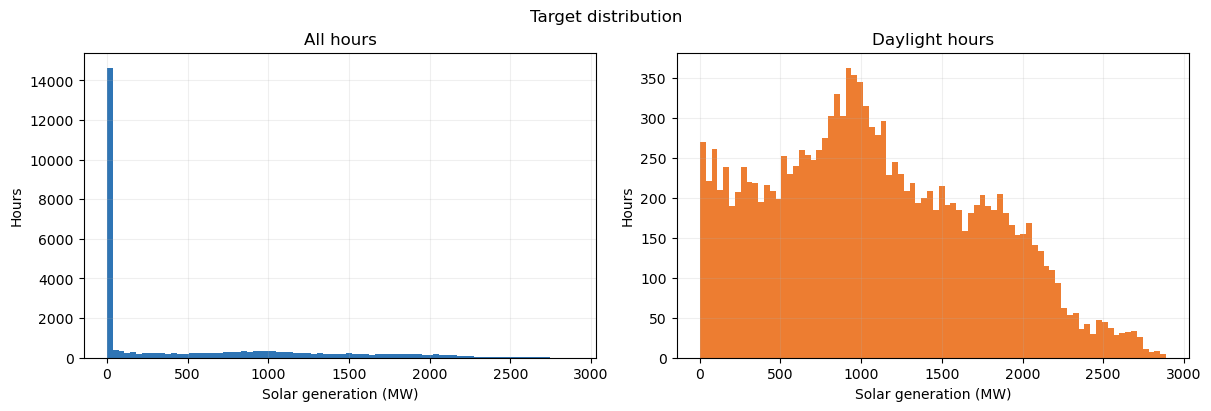

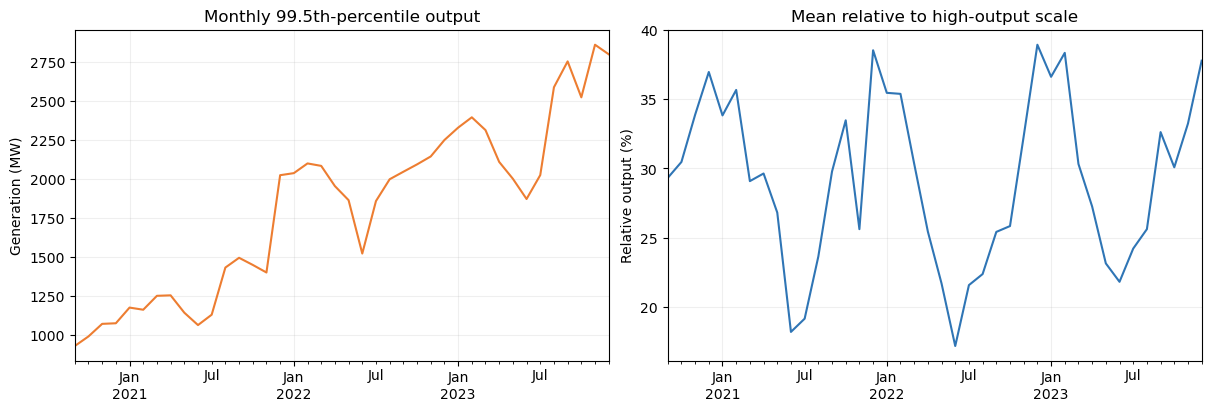

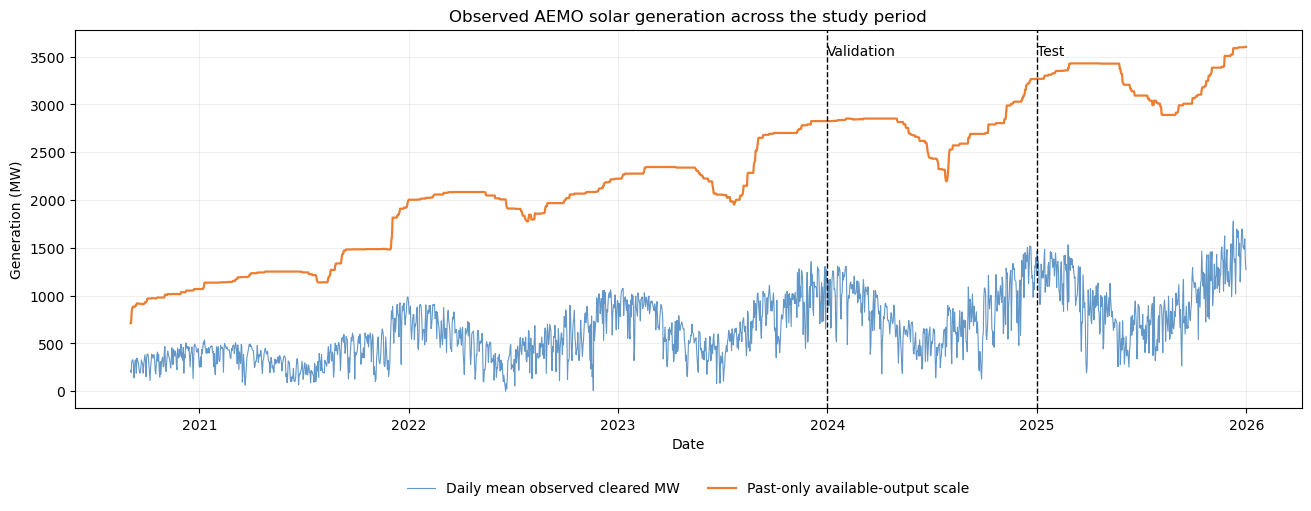

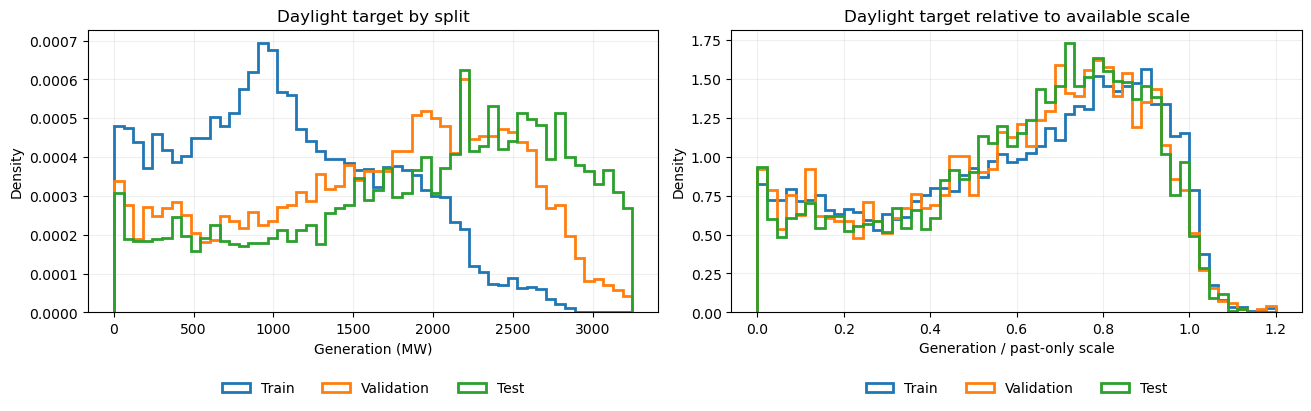

In [5]:
# Restrict model-design EDA to observations available before validation.
eda = data.loc[:"2023-12-31 23:00"].dropna().copy()
EDA_FIGURES = FIGURES / "eda"
EDA_FIGURES.mkdir(exist_ok=True)
display(eda[WEATHER + [TARGET]].describe().T.round(2))

# Target distribution: show the night-time zero mass and the daytime shape.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(eda[TARGET], bins=80, color="#2F75B5")
daylight = eda.loc[eda.sun_up, TARGET]
axes[1].hist(daylight, bins=80, color="#ED7D31")
for ax, title in zip(axes, ["All hours", "Daylight hours"]):
    ax.set(title=title, xlabel="Solar generation (MW)", ylabel="Hours")
fig.suptitle("Target distribution")
fig.savefig(EDA_FIGURES / "target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# A measured-output scale proxy shows fleet-level drift without inventing capacity data.
monthly = eda[TARGET].resample("MS").agg(
    mean_generation="mean", high_output=lambda values: values.quantile(0.995))
monthly["mean_to_high_output_pct"] = 100*monthly.mean_generation/monthly.high_output
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
monthly.high_output.plot(ax=axes[0], color="#ED7D31", title="Monthly 99.5th-percentile output")
monthly.mean_to_high_output_pct.plot(
    ax=axes[1], color="#2F75B5", title="Mean relative to high-output scale")
axes[0].set_ylabel("Generation (MW)")
axes[1].set_ylabel("Relative output (%)")
fig.savefig(EDA_FIGURES / "observed_output_scale.png", dpi=300, bbox_inches="tight")
plt.show()

# Full-period output is shown only to audit temporal coverage and split drift.
daily_actual = data[TARGET].resample("D").mean()
daily_scale = data.available_output_scale.resample("D").last()
fig, ax = plt.subplots(figsize=(13, 5), constrained_layout=True)
ax.plot(daily_actual.index, daily_actual, color="#2F75B5", linewidth=0.8,
        alpha=0.75, label="Daily mean observed cleared MW")
ax.plot(daily_scale.index, daily_scale, color="#ED7D31", linewidth=1.6,
        label="Past-only available-output scale")
for boundary, label in [(pd.Timestamp("2024-01-01", tz=data.index.tz), "Validation"),
                        (pd.Timestamp("2025-01-01", tz=data.index.tz), "Test")]:
    ax.axvline(boundary, color="black", linestyle="--", linewidth=1)
    ax.text(boundary, ax.get_ylim()[1]*0.96, label, ha="left", va="top")
ax.set(title="Observed AEMO solar generation across the study period",
       xlabel="Date", ylabel="Generation (MW)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16),
          ncol=2, frameon=False)
fig.savefig(EDA_FIGURES/"actual_generation_timeline.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

# Daylight distributions reveal target shift between chronological splits.
audit_periods = {"Train": data.loc[:"2023-12-31 23:00"],
                 "Validation": data.loc["2024-01-01":"2024-12-31 23:00"],
                 "Test": data.loc["2025-01-01":"2025-12-31 23:00"]}
bins = np.linspace(0, data[TARGET].quantile(0.995), 55)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for name, frame in audit_periods.items():
    daylight_frame = frame.loc[frame.sun_up]
    axes[0].hist(daylight_frame[TARGET], bins=bins, density=True,
                 histtype="step", linewidth=2, label=name)
    relative_output = daylight_frame[TARGET]/daylight_frame.available_output_scale
    axes[1].hist(relative_output.clip(0, 1.2), bins=np.linspace(0, 1.2, 55),
                 density=True, histtype="step", linewidth=2, label=name)
axes[0].set(title="Daylight target by split", xlabel="Generation (MW)",
            ylabel="Density")
axes[1].set(title="Daylight target relative to available scale",
            xlabel="Generation / past-only scale", ylabel="Density")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.20),
               ncol=3, frameon=False)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.20),
               ncol=3, frameon=False)
fig.savefig(EDA_FIGURES/"target_split_drift.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

### Reading the target and drift figures
The all-hours histogram includes the nighttime mass at zero; the daylight panel shows the distribution the models must fit when solar generation is possible. The monthly high-output series is a measured-output scale proxy, not installed-capacity data.

The full timeline checks temporal coverage and makes the validation and test boundaries visible. The split distributions then show the same target in raw MW and relative to the past-only output scale. A remaining shift in the relative panel cannot be explained by scale growth alone.

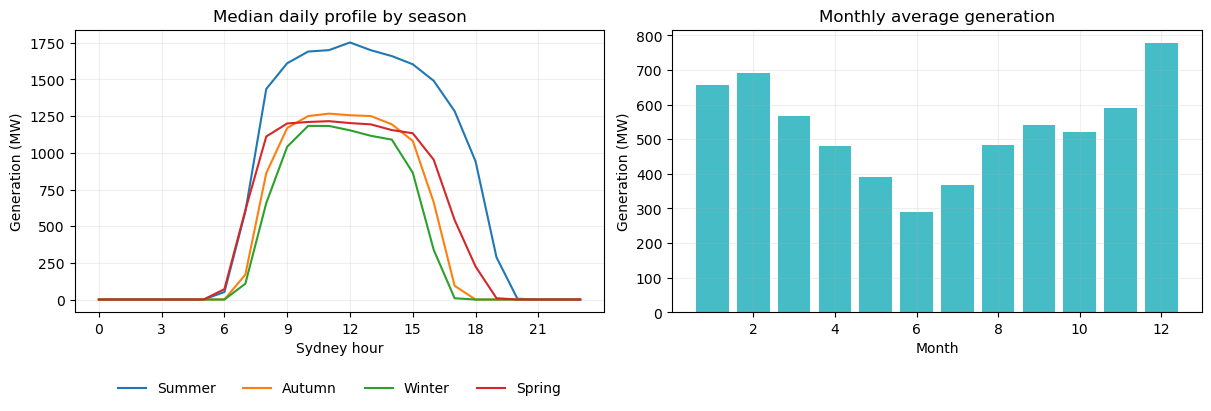

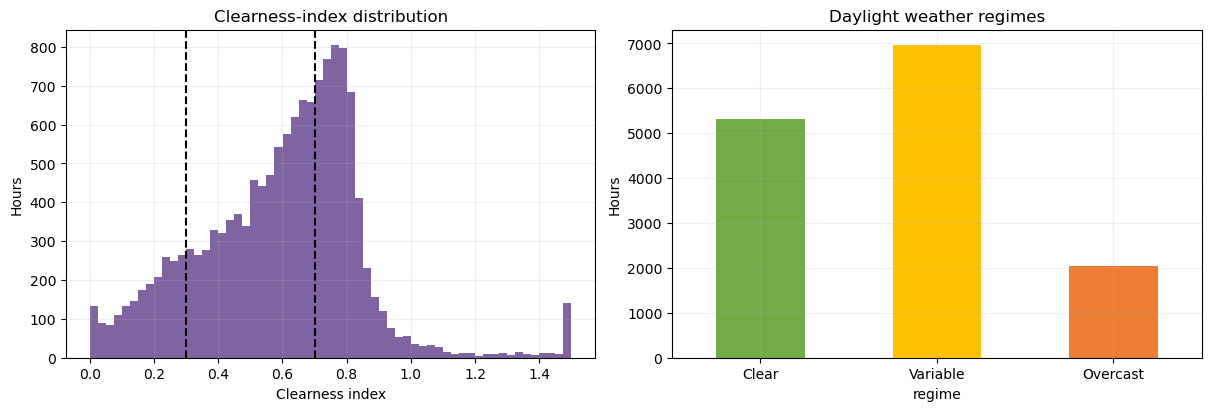

In [6]:
# Hourly and seasonal patterns motivate sequence modelling.
season_map = {12: "Summer", 1: "Summer", 2: "Summer",
              3: "Autumn", 4: "Autumn", 5: "Autumn",
              6: "Winter", 7: "Winter", 8: "Winter",
              9: "Spring", 10: "Spring", 11: "Spring"}
season = pd.Series(eda.index.month, index=eda.index).map(season_map)
seasonal_hourly = eda[TARGET].groupby([season, eda.index.hour]).median().unstack(0)
monthly_generation = eda[TARGET].groupby(eda.index.month).mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name in ["Summer", "Autumn", "Winter", "Spring"]:
    axes[0].plot(seasonal_hourly.index, seasonal_hourly[name], label=name)
axes[0].set(title="Median daily profile by season", xlabel="Sydney hour",
            ylabel="Generation (MW)", xticks=range(0, 24, 3))
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.20),
               ncol=4, frameon=False)
axes[1].bar(range(1, 13), monthly_generation, color="#46BDC6")
axes[1].set(title="Monthly average generation", xlabel="Month", ylabel="Generation (MW)")
fig.savefig(EDA_FIGURES / "hourly_seasonal_patterns.png", dpi=300, bbox_inches="tight")
plt.show()

# First-principles clearness-index regimes used later for evaluation.
eda["regime"] = pd.cut(eda.clearness_index, [-np.inf, 0.3, 0.7, np.inf],
                       labels=["Overcast", "Variable", "Clear"])
regime_day = eda.loc[eda.sun_up]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(regime_day.clearness_index, bins=60, color="#8064A2")
axes[0].axvline(0.3, color="black", linestyle="--"); axes[0].axvline(0.7, color="black", linestyle="--")
axes[0].set(title="Clearness-index distribution", xlabel="Clearness index", ylabel="Hours")
regime_day.regime.value_counts().reindex(["Clear", "Variable", "Overcast"]).plot.bar(
    ax=axes[1], color=["#70AD47", "#FFC000", "#ED7D31"], rot=0,
    title="Daylight weather regimes")
axes[1].set_ylabel("Hours")
fig.savefig(EDA_FIGURES / "clearness_index_regimes.png", dpi=300, bbox_inches="tight")
plt.show()


### Reading the seasonal and weather-regime figures
The hourly curves show how the timing and height of the daily generation profile change by season. Monthly means show the slower annual cycle. Together they support a 24-hour sequence window and cyclical calendar inputs.

Clearness-index thresholds divide daylight observations into overcast, variable and clear regimes. These labels are later reused only to stratify errors; they are not supplied as a categorical model input.

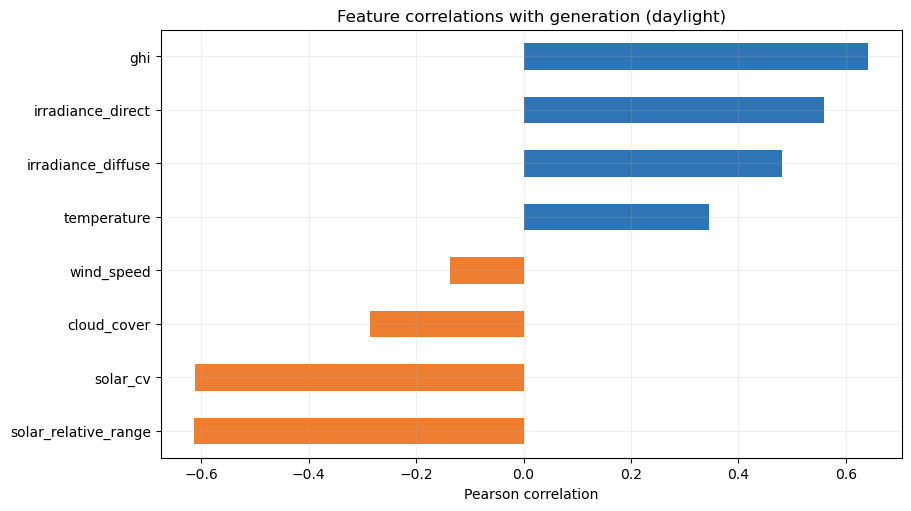

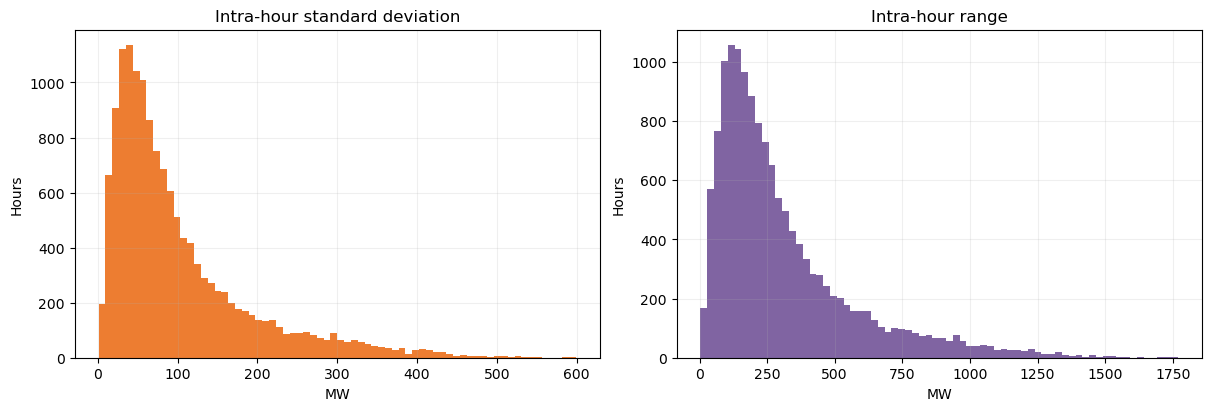

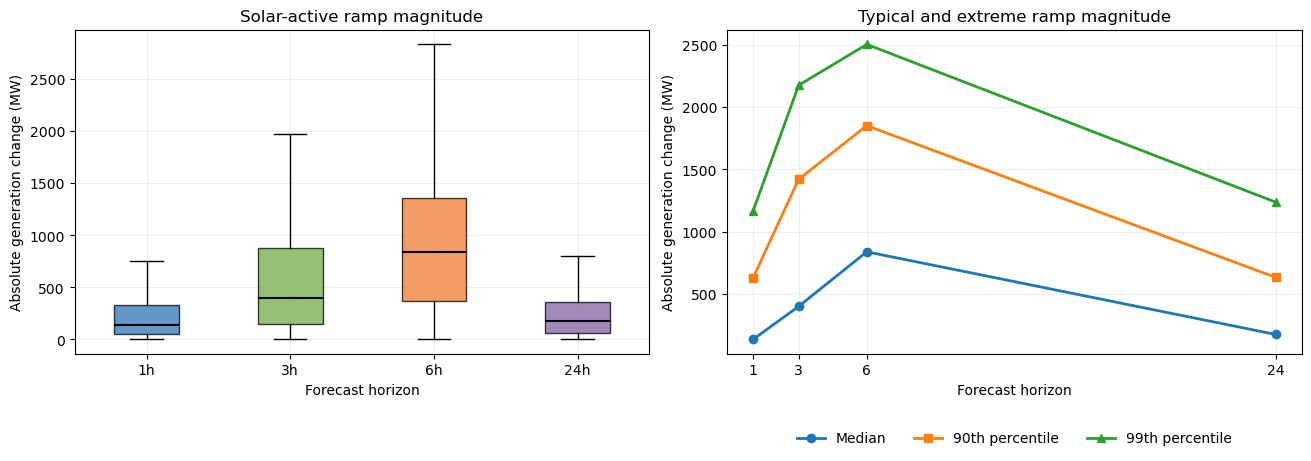

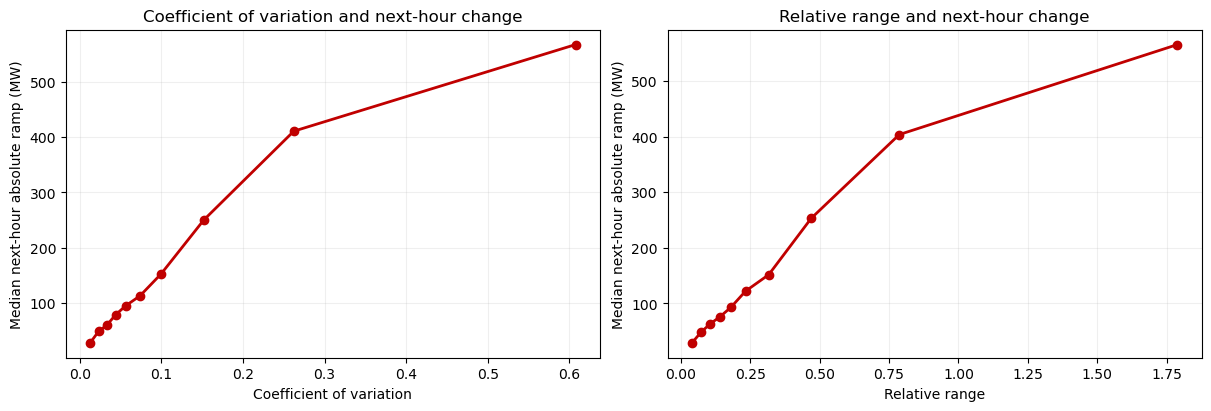

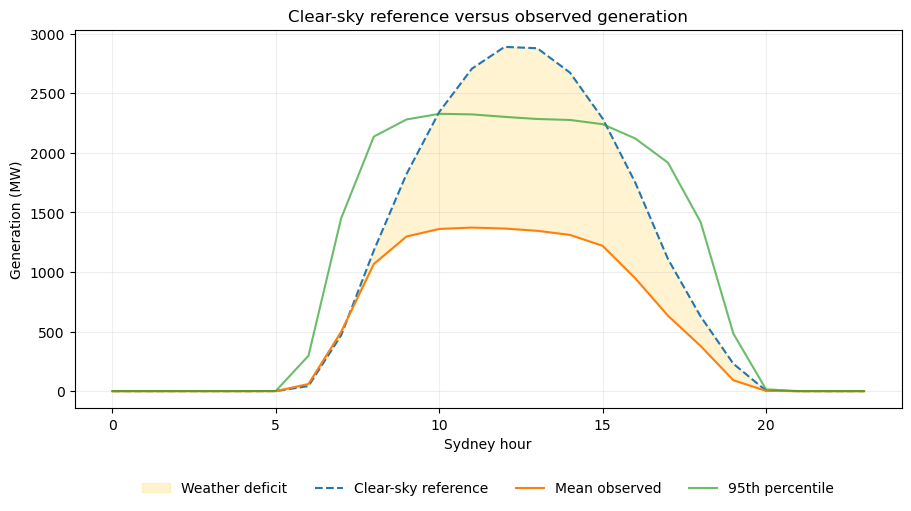

In [7]:
# Feature correlations and the five-minute variability distributions.
corr = eda.loc[eda.sun_up, WEATHER + INTRA_HOUR + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
corr.plot.barh(ax=ax, color=np.where(corr >= 0, "#2F75B5", "#ED7D31"))
ax.set(title="Feature correlations with generation (daylight)", xlabel="Pearson correlation")
fig.savefig(EDA_FIGURES / "feature_correlations.png", dpi=300, bbox_inches="tight")
plt.show()

intra_range = eda.solar_max-eda.solar_min
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(eda.loc[eda.sun_up, "solar_std"], bins=70, color="#ED7D31")
axes[1].hist(intra_range[eda.sun_up], bins=70, color="#8064A2")
axes[0].set(title="Intra-hour standard deviation", xlabel="MW", ylabel="Hours")
axes[1].set(title="Intra-hour range", xlabel="MW", ylabel="Hours")
fig.savefig(EDA_FIGURES / "intra_hour_variability.png", dpi=300, bbox_inches="tight")
plt.show()


# Solar-active ramp magnitudes show forecasting difficulty without a zero spike.
ramp_colours = ["#2F75B5", "#70AD47", "#ED7D31", "#8064A2"]
active_ramps = {}
for h in HORIZONS:
    future_generation = eda[TARGET].shift(-h)
    future_sun = eda.sun_up.shift(-h, fill_value=False).astype(bool)
    active = eda.sun_up | future_sun
    active_ramps[h] = (future_generation-eda[TARGET]).abs().loc[active].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
boxes = axes[0].boxplot(
    [active_ramps[h] for h in HORIZONS], tick_labels=[f"{h}h" for h in HORIZONS],
    showfliers=False, patch_artist=True,
    medianprops={"color": "black", "linewidth": 1.5})
for patch, colour in zip(boxes["boxes"], ramp_colours):
    patch.set_facecolor(colour)
    patch.set_alpha(0.75)
axes[0].set(title="Solar-active ramp magnitude", xlabel="Forecast horizon",
            ylabel="Absolute generation change (MW)")

ramp_quantiles = pd.DataFrame({
    h: active_ramps[h].quantile([0.50, 0.90, 0.99]) for h in HORIZONS}).T
ramp_quantiles.columns = ["Median", "90th percentile", "99th percentile"]
for label, marker in zip(ramp_quantiles, ["o", "s", "^"]):
    axes[1].plot(HORIZONS, ramp_quantiles[label], marker=marker,
                 linewidth=2, label=label)
axes[1].set(title="Typical and extreme ramp magnitude", xlabel="Forecast horizon",
            ylabel="Absolute generation change (MW)", xticks=HORIZONS)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.20),
               ncol=3, frameon=False)
fig.savefig(EDA_FIGURES/"actual_ramp_distribution.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

# Binned associations test whether completed-hour variability signals the next ramp.
future_absolute_ramp = (eda[TARGET].shift(-1)-eda[TARGET]).abs()
next_sun_up = eda.sun_up.shift(-1, fill_value=False).astype(bool)
ramp_sample = eda.loc[eda.sun_up & next_sun_up, INTRA_HOUR].copy()
ramp_sample["next_absolute_ramp"] = future_absolute_ramp.reindex(ramp_sample.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, feature, label in zip(
        axes, INTRA_HOUR, ["Coefficient of variation", "Relative range"]):
    quantile_bin = pd.qcut(ramp_sample[feature], 10, duplicates="drop")
    association = ramp_sample.groupby(quantile_bin, observed=True).agg(
        variability=(feature, "median"),
        next_ramp=("next_absolute_ramp", "median"))
    ax.plot(association.variability, association.next_ramp, marker="o",
            linewidth=2, color="#C00000")
    ax.set(title=f"{label} and next-hour change", xlabel=label,
           ylabel="Median next-hour absolute ramp (MW)")
fig.savefig(EDA_FIGURES/"intra_hour_signal_next_ramp.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

# Solar-geometry reference curve versus observed generation.
profile = eda.groupby(eda.index.hour).agg(
    mean_generation=(TARGET, "mean"),
    p95_generation=(TARGET, lambda values: values.quantile(0.95)),
    toa=("extraterrestrial", "mean"))
profile["clear_sky_reference"] = profile.toa/profile.toa.max()*eda[TARGET].max()
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.fill_between(profile.index, profile.mean_generation, profile.clear_sky_reference,
                color="#FFC000", alpha=0.18, label="Weather deficit")
ax.plot(profile.index, profile.clear_sky_reference, "--", label="Clear-sky reference")
ax.plot(profile.index, profile.mean_generation, label="Mean observed")
ax.plot(profile.index, profile.p95_generation, alpha=0.7, label="95th percentile")
ax.set(title="Clear-sky reference versus observed generation",
       xlabel="Sydney hour", ylabel="Generation (MW)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16),
          ncol=4, frameon=False)
fig.savefig(EDA_FIGURES / "clear_sky_reference.png", dpi=300, bbox_inches="tight")
plt.show()

### Reading the signal and ramp figures
Daylight correlations are screening descriptions, not causal effects or feature-selection rules. The variability histograms show the raw within-hour movement from which the two scale-normalised AEMO inputs are derived.

Ramp plots quantify the forecast challenge at each horizon. The binned next-hour plots provide the EDA link to the research question: a rising relationship would make completed-hour variability a plausible predictor of the next absolute change. The model comparison determines whether that descriptive signal reduces out-of-sample RMSE.

The solar-geometry curve is a physical reference rather than a forecast. Its gap from observed generation reflects weather and other losses that the models must learn from data.

## 5. Chronological train, validation and test split
Training ends on 31 December 2023, validation covers 2024, and evaluation covers 2025. There is no shuffling. A full validation year supports tuning and early stopping across all seasons. The later year remains temporally held out from fitting, but repeated inspection makes its interpretation exploratory.

Rows created by lag and rolling operations are dropped within each split. Hourly-spacing assertions catch gaps before window construction.

In [8]:
# Calendar-year boundaries preserve order and give each holdout all seasons.
splits = {"train": data.loc[:"2023-12-31 23:00"].dropna(),
          "val": data.loc["2024-01-01":"2024-12-31 23:00"].dropna(),
          "test": data.loc["2025-01-01":"2025-12-31 23:00"].dropna()}
assert splits["train"].index.max() < splits["val"].index.min() < splits["test"].index.min()
for name, frame in splits.items():
    deltas = frame.index.to_series().diff().dropna()
    assert frame.index.is_unique and frame.index.is_monotonic_increasing
    assert deltas.ge(pd.Timedelta(hours=1)).all()
    excluded_gap_hours = int((deltas/pd.Timedelta(hours=1)-1).sum())
    print(name, len(frame), "hours; excluded hours inside split:", excluded_gap_hours)
assert splits["train"].loc[lambda x: x[TARGET] > 0, "ghi"].corr(
    splits["train"].loc[lambda x: x[TARGET] > 0, TARGET]) > 0.4


train 29016 hours; excluded hours inside split: 118
val 8782 hours; excluded hours inside split: 2
test 8760 hours; excluded hours inside split: 0


## 6. Build common 24-hour inputs
Every model sees the same 24 completed hourly intervals and predicts one target value at 1, 3, 6 or 24 hours ahead. AEMO uses left-edge hourly labels, so the issue time is one hour after the final input label. The target interval ends exactly `h` elapsed hours after issue.

XGBoost receives each window as a flat vector. The neural models receive the same values in sequence form. Means and standard deviations are estimated from training windows only, then reused for validation and test data.

In [9]:
# Build direct-horizon samples without allowing a window to cross a split.
def make_windows(frame, features, h):
    x = frame[features].to_numpy(dtype=float)
    windows = np.lib.stride_tricks.sliding_window_view(
        x, WINDOW, axis=0).transpose(0, 2, 1)[:-h]
    input_start_label = frame.index[:len(windows)]
    last_input_label = frame.index[WINDOW-1:-h]
    target_label = frame.index[WINDOW-1+h:]
    issue_time = last_input_label+pd.Timedelta(hours=1)
    target_time = target_label+pd.Timedelta(hours=1)
    # Row adjacency is not time adjacency when excluded source hours create gaps.
    contiguous_input = (last_input_label-input_start_label ==
                        pd.Timedelta(hours=WINDOW-1))
    exact_horizon = target_time-issue_time == pd.Timedelta(hours=h)
    valid = contiguous_input & exact_horizon
    windows = windows[valid]
    last_input_label = last_input_label[valid]
    target_label = target_label[valid]
    issue_time = issue_time[valid]
    target_time = target_time[valid]
    y = frame[TARGET].reindex(target_label).to_numpy(dtype=float)
    assert (target_time-issue_time == pd.Timedelta(hours=h)).all()
    assert (last_input_label-input_start_label[valid] ==
            pd.Timedelta(hours=WINDOW-1)).all()
    assert np.isfinite(windows).all() and np.isfinite(y).all()
    assert len(windows) == len(y) == len(issue_time)
    return np.ascontiguousarray(windows), y, issue_time, target_label, target_time

blocks = {}
for feature_set, features in FEATURE_SETS.items():
    for h in HORIZONS:
        raw = {name: make_windows(frame, features, h)
               for name, frame in splits.items()}
        xtrain, ytrain, *_ = raw["train"]
        # Fit scalers on training windows, then reuse them unchanged.
        xmean, xstd = xtrain.mean(axis=(0, 1)), xtrain.std(axis=(0, 1))+1e-8
        ymean, ystd = ytrain.mean(), ytrain.std()+1e-8
        block = {"features": features, "ymean": ymean, "ystd": ystd}
        for name, (x, y, issue, target_label, target_time) in raw.items():
            block[name] = {
                "x": ((x-xmean)/xstd).astype("float32"), "y": y,
                "issue": issue, "target_label": target_label, "target_time": target_time,
                "sun_up": data.sun_up.reindex(target_label).to_numpy(dtype="float32")}
        blocks[feature_set, h] = block
        if feature_set != "weather":
            reference = blocks["weather", h]
            for name in splits:
                assert np.array_equal(block[name]["issue"], reference[name]["issue"])
                assert np.array_equal(block[name]["target_time"], reference[name]["target_time"])
                assert np.array_equal(block[name]["y"], reference[name]["y"])
    print(f"{feature_set}: {len(features)} inputs; {len(block['train']['y']):,} training windows")

predictions = {key: {} for key in blocks}
validation_predictions = {key: {} for key in blocks}
clipped_pct = {key: {} for key in blocks}

def rmse(actual, forecast):
    return float(np.sqrt(np.mean((np.asarray(actual)-np.asarray(forecast))**2)))

weather: 11 inputs; 28,490 training windows
weather_history: 14 inputs; 28,490 training windows
weather_intra: 13 inputs; 28,490 training windows
combined: 16 inputs; 28,490 training windows


## 7. Classical baselines
Three baselines set different levels of forecasting difficulty. Persistence repeats the latest completed hourly value. Rolling climatology estimates the usual output for the target's local hour from earlier observations. SARIMA represents autoregressive and daily seasonal structure.

SARIMA parameters are fitted once on training data. Validation and test observations update its filtered state at each forecast origin without refitting the coefficients. All learned models are evaluated on the same target timestamps as these baselines.

In [10]:
# Rolling climatology uses earlier observations from the target's local hour.
hour_groups = data.groupby(data.index.hour)[TARGET]
climatology = hour_groups.transform(
    lambda values: values.shift(1).rolling(365, min_periods=30).mean())
climatology_lag2 = hour_groups.transform(
    lambda values: values.shift(2).rolling(365, min_periods=30).mean())
previous_same_hour = pd.Series(data.index, index=data.index).groupby(data.index.hour).shift(1)

# Fit SARIMA parameters once; later observations update only its state.
sarima_train = splits["train"][TARGET].asfreq("h")
sarima_validation = splits["val"][TARGET].asfreq("h")
sarima = SARIMAX(sarima_train, order=(1, 1, 1),
                 seasonal_order=(1, 0, 0, 24), trend="n",
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
sarima_state = sarima.extend(sarima_validation)
sarima_at_issue = {h: {} for h in HORIZONS}
needed_issues = set().union(*(set(block["test"]["issue"]) for block in blocks.values()))
for interval_label, observed in splits["test"][TARGET].items():
    sarima_state = sarima_state.extend(pd.Series([observed], index=[interval_label]))
    issue_time = interval_label+pd.Timedelta(hours=1)
    if issue_time in needed_issues:
        forecast = np.maximum(np.asarray(sarima_state.forecast(max(HORIZONS))), 0)
        for h in HORIZONS:
            sarima_at_issue[h][issue_time] = forecast[h-1]

for (feature_set, h), block in blocks.items():
    issue = block["test"]["issue"]
    target_label = block["test"]["target_label"]
    latest_input_label = issue-pd.Timedelta(hours=1)
    predictions[feature_set, h]["Persistence"] = data[TARGET].reindex(
        latest_input_label).to_numpy()
    latest_used = previous_same_hour.reindex(target_label).to_numpy()
    available = latest_used+pd.Timedelta(hours=1) <= issue.to_numpy()
    predictions[feature_set, h]["Rolling climatology"] = np.where(
        available, climatology.reindex(target_label), climatology_lag2.reindex(target_label))
    predictions[feature_set, h]["SARIMA"] = pd.Series(
        sarima_at_issue[h]).reindex(issue).to_numpy()
    for name in ["Persistence", "Rolling climatology", "SARIMA"]:
        assert np.isfinite(predictions[feature_set, h][name]).all()
print("Persistence, rolling climatology and SARIMA are ready.")

Persistence, rolling climatology and SARIMA are ready.


## 8. XGBoost tuning
Tune one shared XGBoost configuration per horizon with a feature-set-neutral objective. Each Optuna trial fits the same proposed settings on all four training blocks and minimises their mean validation RMSE. The selected settings are then held fixed across feature sets, preserving the controlled ablation without favouring either side of a comparison.

XGBoost runs on the CPU because the project environment cannot safely load the PyTorch and AMD-XGBoost HSA runtimes in the same process.

In [11]:
# Select shared settings from the mean validation RMSE across all feature sets.
xgb_settings = {}
for h in HORIZONS:
    def objective(trial):
        params = dict(
            n_estimators=trial.suggest_int("n_estimators", 100, 400),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            max_depth=trial.suggest_int("max_depth", 3, 8),
            subsample=trial.suggest_float("subsample", 0.6, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
            min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
            reg_lambda=trial.suggest_float("reg_lambda", 0.01, 10.0, log=True))
        validation_rmse = []
        for feature_set in PRIMARY_NEURAL_SETS:
            block = blocks[feature_set, h]
            xtrain = block["train"]["x"].reshape(len(block["train"]["y"]), -1)
            xval = block["val"]["x"].reshape(len(block["val"]["y"]), -1)
            model = xgb.XGBRegressor(
                device="cpu", tree_method="hist", importance_type="gain",
                n_jobs=os.cpu_count(), random_state=SEEDS[0], **params)
            model.fit(xtrain, block["train"]["y"], verbose=False)
            validation_rmse.append(rmse(
                block["val"]["y"], np.maximum(model.predict(xval), 0)))
        trial.set_user_attr("set_rmse", dict(zip(PRIMARY_NEURAL_SETS, validation_rmse)))
        return float(np.mean(validation_rmse))

    started = time.perf_counter()
    study = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEEDS[0]))
    study.optimize(objective, n_trials=TRIALS)
    xgb_settings[h] = dict(study.best_params)
    print(f"XGBoost neutral tuning {h}h: mean {study.best_value:.2f} MW, "
          f"set RMSE {study.best_trial.user_attrs['set_rmse']}, "
          f"{xgb_settings[h]['n_estimators']} trees, "
          f"{time.perf_counter()-started:.1f}s")

XGBoost neutral tuning 1h: mean 316.49 MW, set RMSE {'weather': 502.39468631303185, 'weather_history': 148.1758421095265, 'weather_intra': 472.42085672674, 'combined': 142.95252581274437}, 362 trees, 228.3s
XGBoost neutral tuning 3h: mean 376.17 MW, set RMSE {'weather': 510.452993871521, 'weather_history': 252.7575285002569, 'weather_intra': 493.7875764257982, 'combined': 247.68475345699193}, 336 trees, 219.7s
XGBoost neutral tuning 6h: mean 405.43 MW, set RMSE {'weather': 521.9075929402204, 'weather_history': 297.5137908282479, 'weather_intra': 507.0985841501371, 'combined': 295.207151451044}, 353 trees, 180.8s
XGBoost neutral tuning 24h: mean 429.07 MW, set RMSE {'weather': 530.251562631481, 'weather_history': 332.858792478008, 'weather_intra': 523.8011475408674, 'combined': 329.3625035975231}, 347 trees, 114.3s


### 8.1 Final XGBoost fits
Fit the selected horizon configuration to each feature set. Only the four `combined` models are retained after prediction because they are needed for feature-importance analysis; validation and test forecasts are cached for every fitted model.

In [12]:
# Reuse each horizon's settings across all four information sets.
xgb_training = []
xgb_combined_models = {}
for feature_set in FEATURE_SETS:
    for h in HORIZONS:
        block = blocks[feature_set, h]
        started = time.perf_counter()
        model = xgb.XGBRegressor(
            device="cpu", tree_method="hist", importance_type="gain",
            n_jobs=os.cpu_count(),
            random_state=SEEDS[0], **xgb_settings[h])
        xtrain = block["train"]["x"].reshape(len(block["train"]["y"]), -1)
        model.fit(xtrain, block["train"]["y"], verbose=False)
        # Retain only combined models needed for importance diagnostics.
        if feature_set == "combined":
            xgb_combined_models[h] = model
        for split, store in [("val", validation_predictions),
                             ("test", predictions)]:
            x = block[split]["x"].reshape(len(block[split]["y"]), -1)
            raw = model.predict(x)
            store[feature_set, h]["XGBoost"] = np.maximum(raw, 0)
            if split == "test":
                clipped_pct[feature_set, h]["XGBoost"] = 100*float((raw < 0).mean())
        xgb_training.append({"feature_set": feature_set, "horizon": h,
                             "fit_seconds": time.perf_counter()-started,
                             **xgb_settings[h]})
        print(f"XGBoost {feature_set} {h}h complete in "
              f"{xgb_training[-1]['fit_seconds']:.1f}s")

XGBoost weather 1h complete in 3.0s
XGBoost weather 3h complete in 1.5s
XGBoost weather 6h complete in 1.6s
XGBoost weather 24h complete in 0.7s
XGBoost weather_history 1h complete in 3.8s
XGBoost weather_history 3h complete in 1.9s
XGBoost weather_history 6h complete in 2.1s
XGBoost weather_history 24h complete in 0.8s
XGBoost weather_intra 1h complete in 3.4s
XGBoost weather_intra 3h complete in 1.9s
XGBoost weather_intra 6h complete in 2.0s
XGBoost weather_intra 24h complete in 0.8s
XGBoost combined 1h complete in 4.7s
XGBoost combined 3h complete in 2.3s
XGBoost combined 6h complete in 2.6s
XGBoost combined 24h complete in 0.9s


### 8.2 XGBoost feature importance
XGBoost assigns gain importance to each feature at each of the 24 lag positions. Summing those values by variable gives one readable share per input and horizon.

Treat this as a model-use diagnostic. Correlated inputs can divide or displace gain, and a high value does not show that a variable caused the forecast improvement.

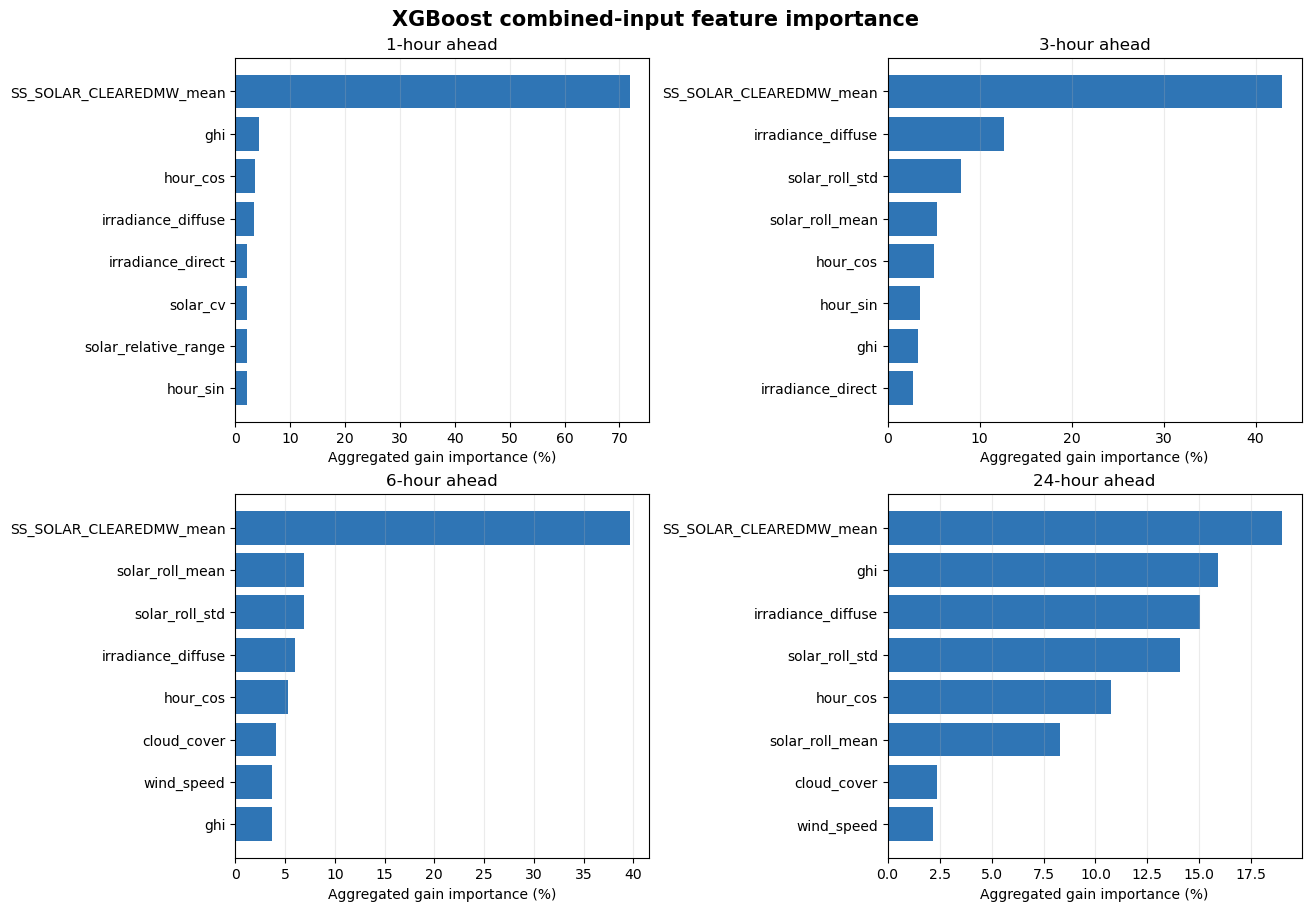

horizon,1,3,6,24
feature,,,,
SS_SOLAR_CLEAREDMW_mean,71.860001,42.860001,39.619999,18.969999
clearness_index,1.630000,1.970000,2.350000,0.960000
cloud_cover,0.950000,2.500000,4.100000,2.380000
day_cos,0.510000,1.380000,2.500000,1.730000
day_sin,0.610000,1.690000,3.670000,1.920000
ghi,4.340000,3.270000,3.680000,15.890000
hour_cos,3.600000,5.070000,5.250000,10.770000
hour_sin,2.060000,3.510000,1.830000,1.630000
irradiance_diffuse,3.330000,12.670000,6.010000,15.030000


In [13]:
# Sum gain across lag positions so each input has one share per horizon.
xgb_importance_rows = []
for h in HORIZONS:
    features = blocks["combined", h]["features"]
    lag_importance = xgb_combined_models[h].feature_importances_.reshape(
        WINDOW, len(features))
    aggregated = lag_importance.sum(axis=0)
    aggregated = aggregated/aggregated.sum()
    xgb_importance_rows.extend(
        {"horizon": h, "feature": feature, "gain_share": value}
        for feature, value in zip(features, aggregated))
xgb_importance = pd.DataFrame(xgb_importance_rows)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for h, ax in zip(HORIZONS, axes.flat):
    ranking = xgb_importance.loc[xgb_importance.horizon.eq(h)].nlargest(
        8, "gain_share").sort_values("gain_share")
    ax.barh(ranking.feature, 100*ranking.gain_share, color="#2F75B5")
    ax.set(title=f"{h}-hour ahead", xlabel="Aggregated gain importance (%)")
    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)
fig.suptitle("XGBoost combined-input feature importance",
             fontsize=15, fontweight="bold")
fig.savefig(FIGURES/"xgboost_feature_importance.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()
display(xgb_importance.pivot(
    index="feature", columns="horizon", values="gain_share").mul(100).round(2))

## 9. Neural models
The unidirectional LSTM is the standard sequence benchmark. A CNN-BiLSTM first extracts short local patterns with a convolution, then processes the compressed sequence in both directions. A matched physics-guided version uses the identical architecture and initial seeds but adds penalties for negative and non-zero nighttime forecasts.

The matched CNN-BiLSTM pair isolates the effect of the loss penalties from convolution, bidirectionality, pooling and head size. Comparisons with the simpler LSTM remain procedure-level because those architectural components change together.

All three neural procedures use all four information sets, so both the meteorology-only and history-controlled intra-hour contrasts are evaluated across model families. Five final-profile seeds expose training variation; their forecasts are averaged for the headline neural procedures. Early stopping uses validation loss and restores the best checkpoint for each run.

In [14]:
# Standard recurrent benchmark using the final state of the 24-hour window.
class LSTMForecaster(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.lstm = nn.LSTM(n_features, 64, batch_first=True)
        self.head = nn.Linear(64, 1)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        return self.head(hidden[-1]).squeeze(-1)


# Convolution compresses local patterns before bidirectional recurrence.
class PhysicsCNNBiLSTM(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(n_features, 32, 3, padding=1),
                                  nn.ReLU(), nn.MaxPool1d(2))
        self.lstm = nn.LSTM(32, 64, batch_first=True, bidirectional=True)
        self.head = nn.Linear(128, 1)

    def forward(self, x):
        sequence = self.conv(x.transpose(1, 2)).transpose(1, 2)
        _, (hidden, _) = self.lstm(sequence)
        return self.head(torch.cat([hidden[-2], hidden[-1]], dim=1)).squeeze(-1)


def train_neural(model, tensors, physics=False, zero_norm=None):
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    history = {"train": [], "val": []}
    xtrain, ytrain, sun_train = tensors["train"]
    xval, yval, _ = tensors["val"]

    # Soft penalties discourage negative and nighttime physical violations.
    def training_loss(prediction, target, sun_up):
        loss = loss_fn(prediction, target)
        if physics:
            negative = torch.relu(zero_norm-prediction).square().mean()
            night = ((prediction-zero_norm)*(1-sun_up)).square().mean()
            loss = loss+0.1*(negative+night)
        return loss

    best_loss, best_epoch, wait, best_state = float("inf"), 0, 0, None
    for epoch in range(EPOCHS):
        model.train()
        epoch_squared_error = torch.zeros((), device=DEVICE)
        order = torch.randperm(len(xtrain), device=DEVICE)
        for start in range(0, len(order), BATCH):
            batch = order[start:start+BATCH]
            optimizer.zero_grad(set_to_none=True)
            prediction = model(xtrain[batch])
            loss = training_loss(prediction, ytrain[batch], sun_train[batch])
            epoch_squared_error += loss_fn(
                prediction, ytrain[batch]).detach()*len(batch)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.inference_mode():
            val_loss = loss_fn(model(xval), yval).item()
        history["train"].append(float(torch.sqrt(
            epoch_squared_error/len(xtrain)).cpu()))
        history["val"].append(float(np.sqrt(val_loss)))
        # Save the best validation checkpoint rather than the final epoch.
        if val_loss < best_loss:
            best_loss, best_epoch, wait = val_loss, epoch+1, 0
            best_state = deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    if best_state is None:
        raise RuntimeError("Neural training produced no finite validation loss")
    model.load_state_dict(best_state)
    return model, best_epoch, history


seed_scores, neural_training, neural_histories = [], [], []

def train_neural_family(name, factory, physics=False):
    for feature_set in PRIMARY_NEURAL_SETS:
        for h in HORIZONS:
            block = blocks[feature_set, h]
            tensors = {split: (
                torch.tensor(block[split]["x"], device=DEVICE),
                torch.tensor((block[split]["y"]-block["ymean"])/block["ystd"],
                             dtype=torch.float32, device=DEVICE),
                torch.tensor(block[split]["sun_up"], device=DEVICE))
                for split in ("train", "val", "test")}
            zero_norm = torch.tensor(-block["ymean"]/block["ystd"],
                                     dtype=torch.float32, device=DEVICE)
            forecasts = {"val": [], "test": []}
            started = time.perf_counter()
            epochs = []
            # Independent seeds expose variation from neural initialisation.
            for seed in SEEDS:
                random.seed(seed)
                np.random.seed(seed)
                torch.manual_seed(seed)
                if torch.cuda.is_available():
                    torch.cuda.manual_seed_all(seed)
                model, best_epoch, history = train_neural(
                    factory(len(block["features"])).to(DEVICE), tensors,
                    physics=physics, zero_norm=zero_norm)
                epochs.append(best_epoch)
                neural_histories.append({"model": name, "feature_set": feature_set,
                    "horizon": h, "seed": seed, "history": history})
                model.eval()
                with torch.inference_mode():
                    for split in forecasts:
                        pred = (model(tensors[split][0]).cpu().numpy()*block["ystd"]
                                + block["ymean"])
                        forecasts[split].append(pred)
                seed_scores.append({"feature_set": feature_set, "model": name,
                    "horizon": h, "seed": seed,
                    "RMSE_MW": rmse(block["test"]["y"],
                                    np.maximum(forecasts["test"][-1], 0))})
                neural_training.append({"feature_set": feature_set, "model": name,
                    "horizon": h, "seed": seed, "best_epoch": best_epoch,
                    "val_RMSE_MW": rmse(block["val"]["y"],
                                        np.maximum(forecasts["val"][-1], 0))})
            # Average seed forecasts before computing the headline metrics.
            for split, store in [("val", validation_predictions),
                                 ("test", predictions)]:
                raw = np.mean(forecasts[split], axis=0)
                store[feature_set, h][name] = np.maximum(raw, 0)
                if split == "test":
                    clipped_pct[feature_set, h][name] = 100*float((raw < 0).mean())
            print(f"{name} {feature_set} {h}h: {len(SEEDS)} seeds, "
                  f"best epochs {min(epochs)}-{max(epochs)}, "
                  f"{time.perf_counter()-started:.1f}s")
            del tensors, model

### 9.1 LSTM training
Train the LSTM and cache its validation and test forecasts. This stage has its own cell so a later physics-model interruption does not force the LSTM fits to be repeated.

In [15]:
train_neural_family("LSTM", LSTMForecaster, physics=False)
print("LSTM training complete.")

LSTM weather 1h: 5 seeds, best epochs 10-21, 25.1s
LSTM weather 3h: 5 seeds, best epochs 9-39, 27.5s
LSTM weather 6h: 5 seeds, best epochs 14-34, 26.2s
LSTM weather 24h: 5 seeds, best epochs 6-14, 18.3s
LSTM weather_history 1h: 5 seeds, best epochs 47-59, 43.1s
LSTM weather_history 3h: 5 seeds, best epochs 22-45, 35.9s
LSTM weather_history 6h: 5 seeds, best epochs 14-27, 24.4s
LSTM weather_history 24h: 5 seeds, best epochs 9-16, 19.3s
LSTM weather_intra 1h: 5 seeds, best epochs 20-41, 29.3s
LSTM weather_intra 3h: 5 seeds, best epochs 24-40, 31.5s
LSTM weather_intra 6h: 5 seeds, best epochs 20-29, 28.2s
LSTM weather_intra 24h: 5 seeds, best epochs 15-25, 23.3s
LSTM combined 1h: 5 seeds, best epochs 51-77, 49.5s
LSTM combined 3h: 5 seeds, best epochs 22-45, 31.1s
LSTM combined 6h: 5 seeds, best epochs 11-22, 23.5s
LSTM combined 24h: 5 seeds, best epochs 8-10, 17.6s
LSTM training complete.


### 9.2 Matched CNN-BiLSTM control and physics-guided training
Train an unconstrained CNN-BiLSTM and the physics-guided version with identical feature sets, horizons, seeds, architecture, optimiser and early-stopping rule. The only planned difference within this matched pair is the two soft physical penalties.

In [16]:
train_neural_family("CNN-BiLSTM", PhysicsCNNBiLSTM, physics=False)
print("Matched CNN-BiLSTM control training complete.")
train_neural_family("Physics-guided CNN-BiLSTM", PhysicsCNNBiLSTM, physics=True)
print("Physics-guided CNN-BiLSTM training complete.")

CNN-BiLSTM weather 1h: 5 seeds, best epochs 10-23, 40.9s
CNN-BiLSTM weather 3h: 5 seeds, best epochs 11-19, 42.5s
CNN-BiLSTM weather 6h: 5 seeds, best epochs 7-29, 41.8s
CNN-BiLSTM weather 24h: 5 seeds, best epochs 8-19, 40.8s
CNN-BiLSTM weather_history 1h: 5 seeds, best epochs 52-68, 98.0s
CNN-BiLSTM weather_history 3h: 5 seeds, best epochs 19-26, 49.2s
CNN-BiLSTM weather_history 6h: 5 seeds, best epochs 15-29, 50.4s
CNN-BiLSTM weather_history 24h: 5 seeds, best epochs 7-17, 37.4s
CNN-BiLSTM weather_intra 1h: 5 seeds, best epochs 16-37, 52.3s
CNN-BiLSTM weather_intra 3h: 5 seeds, best epochs 12-29, 45.6s
CNN-BiLSTM weather_intra 6h: 5 seeds, best epochs 9-24, 43.1s
CNN-BiLSTM weather_intra 24h: 5 seeds, best epochs 8-20, 39.8s
CNN-BiLSTM combined 1h: 5 seeds, best epochs 40-67, 87.2s
CNN-BiLSTM combined 3h: 5 seeds, best epochs 19-33, 51.3s
CNN-BiLSTM combined 6h: 5 seeds, best epochs 10-31, 49.8s
CNN-BiLSTM combined 24h: 5 seeds, best epochs 8-16, 43.1s
Matched CNN-BiLSTM control tra

### 9.3 Neural convergence
The curves show normalised predictive RMSE for training and validation, averaged across the five `combined` runs. Runs can stop at different epochs, so each plotted mean uses only seeds that reached that epoch. The matched CNN-BiLSTM pair makes the penalty effect visible under an otherwise identical architecture.

These plots check convergence and overfitting. They do not compare test performance, and the training curve excludes the physics penalties so that all three neural procedures use the same vertical scale.

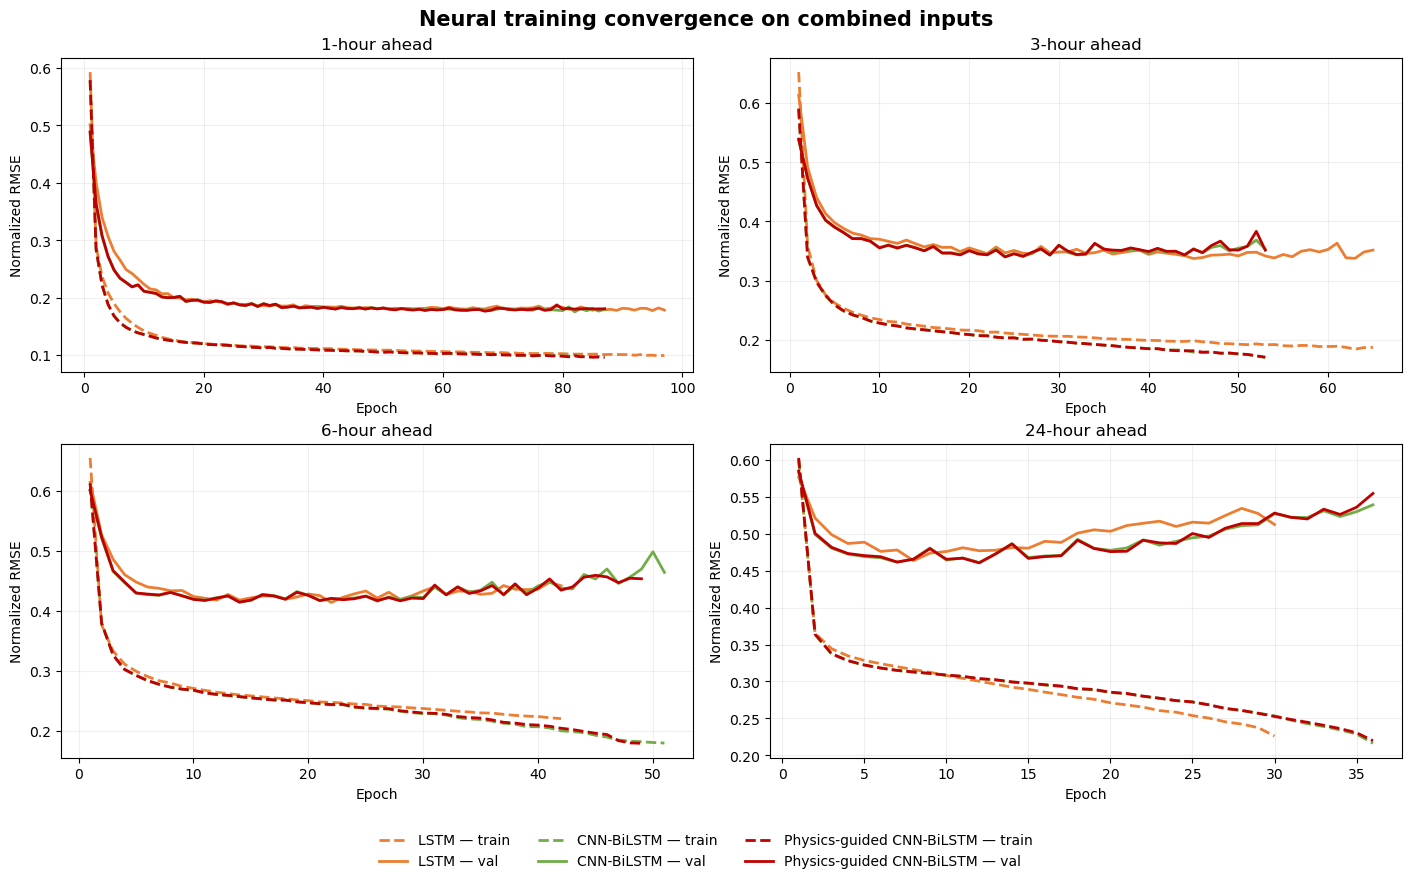

In [17]:
def mean_history(records, split):
    """Average variable-length early-stopping histories without padding bias."""
    length = max(len(record["history"][split]) for record in records)
    values = np.full((len(records), length), np.nan)
    for row, record in enumerate(records):
        history = record["history"][split]
        values[row, :len(history)] = history
    return np.nanmean(values, axis=0)

# Plot only the controlled combined-input runs used in the main results.
fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for h, ax in zip(HORIZONS, axes.flat):
    for name in ["LSTM", "CNN-BiLSTM", "Physics-guided CNN-BiLSTM"]:
        records = [record for record in neural_histories
                   if record["model"] == name
                   and record["feature_set"] == "combined"
                   and record["horizon"] == h]
        for split, style in [("train", "--"), ("val", "-")]:
            values = mean_history(records, split)
            ax.plot(np.arange(1, len(values)+1), values, linestyle=style,
                    color={"LSTM": "#ED7D31", "CNN-BiLSTM": "#70AD47",
                           "Physics-guided CNN-BiLSTM": "#C00000"}[name],
                    linewidth=2, label=f"{name} — {split}")
    ax.set(title=f"{h}-hour ahead", xlabel="Epoch",
           ylabel="Normalized RMSE")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Neural training convergence on combined inputs",
             fontsize=15, fontweight="bold")
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.02),
           ncol=3, frameon=False)
fig.savefig(FIGURES/"neural_convergence.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

## 10. Ensemble and results
The secondary ensemble averages the four learned forecasts using inverse validation-RMSE weights. Its weights never use the test set. It remains descriptive because validation weighting does not guarantee a lower test error than the best member.

RMSE in MW is the primary metric. MAE, output-scale-relative RMSE, test-peak-normalised RMSE, bias, R-squared, daylight RMSE, persistence skill and clipping frequency describe different parts of the error. Both intra-hour contrasts are evaluated for all four learned procedures, and each procedure supplies the complete 2 x 2 decomposition.

Paired moving-block intervals use 24, 48 and 168-hour blocks. Diebold-Mariano tests use `h-1`, 24-hour and 168-hour bandwidths, with Bonferroni correction within each stated test family. These intervals condition on the final forecasts and do not include neural training-seed, XGBoost model-selection or uncertainty from excluding conflicting legacy records. Because the 2025 outcomes have already been inspected, the results are exploratory evidence for this evaluation year rather than confirmation on untouched data.

In [18]:
learned = ["XGBoost", "LSTM", "CNN-BiLSTM",
           "Physics-guided CNN-BiLSTM"]
# Display labels distinguish the evaluated procedures without renaming prediction keys.
procedure_label = {"XGBoost": "XGBoost (single fit)",
                   "LSTM": "LSTM (five-seed mean)",
                   "CNN-BiLSTM": "CNN-BiLSTM (five-seed mean)",
                   "Physics-guided CNN-BiLSTM":
                       "Physics CNN-BiLSTM (five-seed mean)"}

# Small p-values are formatted as bounds rather than rounded to zero.
def format_p_value(value):
    return "<.0001" if value < 1e-4 else f"{value:.4f}"
# Inverse validation RMSE gives stronger members more ensemble weight.
weights = []
for feature_set in PRIMARY_NEURAL_SETS:
    for h in HORIZONS:
        block = blocks[feature_set, h]
        inverse = np.array([
            1/rmse(block["val"]["y"], validation_predictions[feature_set, h][m])
            for m in learned])
        weight = inverse/inverse.sum()
        predictions[feature_set, h]["Ensemble"] = sum(
            w*predictions[feature_set, h][m] for m, w in zip(learned, weight))
        clipped_pct[feature_set, h]["Ensemble"] = 0.0
        weights.append({"feature_set": feature_set, "horizon": h,
                        **dict(zip(learned, weight))})

# Score every forecast against the same target vector within each block.
rows = []
for (feature_set, h), block in blocks.items():
    actual = block["test"]["y"]
    target_label = block["test"]["target_label"]
    latest_input_label = block["test"]["issue"]-pd.Timedelta(hours=1)
    daylight = data.ghi.reindex(target_label).to_numpy() > 20
    scale = data.available_output_scale.reindex(latest_input_label).to_numpy()
    assert np.isfinite(scale).all() and (scale > 0).all()
    reference = rmse(actual, predictions[feature_set, h]["Persistence"])
    for name, pred in predictions[feature_set, h].items():
        assert pred.shape == actual.shape and np.isfinite(pred).all()
        error = pred-actual
        score = rmse(actual, pred)
        rows.append({"feature_set": feature_set, "horizon": h, "model": name,
            "RMSE_MW": score,
            "relative_RMSE_pct": 100*np.sqrt(np.mean((error/scale)**2)),
            "nRMSE_peak_pct": 100*score/actual.max(),
            "MAE_MW": float(np.abs(error).mean()), "bias_MW": float(error.mean()),
            "R2": 1-float(np.sum(error**2)/np.sum((actual-actual.mean())**2)),
            "daylight_RMSE": rmse(actual[daylight], pred[daylight]),
            "skill_persistence_pct": 100*(1-score/reference),
            "clipped_pct": clipped_pct[feature_set, h].get(name, 0.0)})
results = pd.DataFrame(rows)

models = learned+["Ensemble"]
comparison = results.loc[results.model.isin(models)].pivot(
    index=["model", "horizon"], columns="feature_set", values="RMSE_MW")
comparison["history_gain_pct"] = 100*(comparison.weather-comparison.weather_history)/comparison.weather
comparison["intra_gain_without_history_pct"] = 100*(comparison.weather-comparison.weather_intra)/comparison.weather
comparison["controlled_intra_gain_pct"] = 100*(comparison.weather_history-comparison.combined)/comparison.weather_history
print("Factorial feature gains across learned procedures:")
display(comparison.round(2))

# Resample contiguous days so intervals retain short-range error dependence.
def moving_block_gain_interval(actual, reference_pred, candidate_pred, target_time,
                               block_hours, samples=2000):
    """Return a paired RMSE-gain interval from contiguous daily loss blocks."""
    errors = pd.DataFrame({"reference": (reference_pred-actual)**2,
                           "candidate": (candidate_pred-actual)**2}, index=target_time)
    daily = errors.groupby(errors.index.normalize()).mean()
    block_days = max(1, int(np.ceil(block_hours/24)))
    blocks_needed = int(np.ceil(len(daily)/block_days))
    rng = np.random.default_rng(42+block_hours)
    starts = rng.integers(0, len(daily)-block_days+1, (samples, blocks_needed))
    draw = (starts[..., None]+np.arange(block_days)).reshape(samples, -1)[:, :len(daily)]
    ref_rmse = np.sqrt(daily.reference.to_numpy()[draw].mean(axis=1))
    candidate_rmse = np.sqrt(daily.candidate.to_numpy()[draw].mean(axis=1))
    return np.quantile(100*(ref_rmse-candidate_rmse)/ref_rmse, [0.025, 0.975])

intervals = []
ablation_pairs = [
    ("weather", "weather_history", "Hourly-history addition",
     "history_gain_pct", learned),
    ("weather", "weather_intra", "Intra-hour addition without history",
     "intra_gain_without_history_pct", learned),
    ("weather_history", "combined", "Controlled intra-hour addition",
     "controlled_intra_gain_pct", models)]
for reference_set, candidate_set, label, gain_column, supported_models in ablation_pairs:
    for name in supported_models:
        for h in HORIZONS:
            block = blocks["combined", h]
            for block_hours in [24, 48, 168]:
                low, high = moving_block_gain_interval(
                    block["test"]["y"], predictions[reference_set, h][name],
                    predictions[candidate_set, h][name], block["test"]["target_time"],
                    block_hours)
                intervals.append({"comparison": label, "model": name, "horizon": h,
                    "block_hours": block_hours,
                    "gain_pct": comparison.loc[(name, h), gain_column],
                    "CI_low": low, "CI_high": high})
interval_results = pd.DataFrame(intervals)
print("Paired moving-block 95% intervals with dependence sensitivity:")
display(interval_results.round(2))

# Newey-West variance adjusts the loss-difference test for serial correlation.
def dm_test(error_a, error_b, lag):
    difference = error_a**2-error_b**2
    centered, n = difference-difference.mean(), len(difference)
    variance = np.mean(centered**2)
    for offset in range(1, min(lag, n-1)+1):
        covariance = np.mean(centered[offset:]*centered[:-offset])
        variance += 2*(1-offset/(lag+1))*covariance
    statistic = difference.mean()/np.sqrt(max(variance/n, 1e-12))
    return statistic, 2*norm.sf(abs(statistic))

dm_rows = []
dm_specs = [
    ("Intra-hour addition without history", "weather", "weather_intra"),
    ("Controlled intra-hour addition", "weather_history", "combined")]
for comparison_name, reference_set, candidate_set in dm_specs:
    for bandwidth_rule in ["h-1", "24h", "168h"]:
        for name in learned:
            for h in HORIZONS:
                actual = blocks["combined", h]["test"]["y"]
                lag = h-1 if bandwidth_rule == "h-1" else int(bandwidth_rule[:-1])
                statistic, p_value = dm_test(
                    predictions[candidate_set, h][name]-actual,
                    predictions[reference_set, h][name]-actual, lag)
                dm_rows.append({"comparison": comparison_name,
                    "bandwidth": bandwidth_rule, "lag": lag,
                    "model": name, "horizon": h,
                    "DM_stat": statistic, "p_raw": p_value})
dm_results = pd.DataFrame(dm_rows)
dm_results["p_bonferroni"] = dm_results.groupby(
    ["comparison", "bandwidth"]).p_raw.transform(
    lambda values: np.minimum(values*len(values), 1))
dm_results["significant_0.05"] = dm_results.p_bonferroni < 0.05
print("Diebold–Mariano sensitivity: negative favours the added intra-hour inputs:")
dm_display = dm_results.round(4).copy()
for column in ["p_raw", "p_bonferroni"]:
    dm_display[column] = dm_results[column].map(format_p_value)
display(dm_display)

# Scale-normalised errors test whether conclusions depend on the changing MW level.
relative = results.loc[results.model.isin(models)].pivot(
    index=["model", "horizon"], columns="feature_set", values="relative_RMSE_pct")
relative["intra_gain_without_history_pct"] = 100*(relative.weather-relative.weather_intra)/relative.weather
relative["controlled_intra_gain_pct"] = 100*(relative.weather_history-relative.combined)/relative.weather_history
relative["history_gain_pct"] = 100*(relative.weather-relative.weather_history)/relative.weather
print("Sensitivity using a trailing 90-day 99.5th-percentile output scale:")
display(relative.round(2))

# Target-time regimes are evaluation strata, never prediction inputs.
regime_rows = []
for name in models:
    for h in HORIZONS:
        block = blocks["combined", h]
        actual = block["test"]["y"]
        kt = data.clearness_index.reindex(block["test"]["target_label"]).to_numpy()
        sun = data.sun_up.reindex(block["test"]["target_label"]).to_numpy()
        regimes = np.select([kt < 0.3, kt < 0.7],
                            ["Overcast", "Variable"], default="Clear")
        for regime in ["Overcast", "Variable", "Clear"]:
            mask = sun & (regimes == regime)
            reference_rmse = rmse(
                actual[mask], predictions["weather_history", h][name][mask])
            candidate_rmse = rmse(
                actual[mask], predictions["combined", h][name][mask])
            regime_rows.append({"model": name, "horizon": h, "regime": regime,
                "hours": mask.sum(), "weather_history_RMSE": reference_rmse,
                "combined_RMSE": candidate_rmse,
                "gain_pct": 100*(reference_rmse-candidate_rmse)/reference_rmse})
regime_results = pd.DataFrame(regime_rows)
print("Controlled intra-hour gain by daylight weather regime:")
display(regime_results.round(2))

metric_columns = ["horizon", "model", "RMSE_MW", "relative_RMSE_pct",
                  "nRMSE_peak_pct", "MAE_MW", "bias_MW", "R2",
                  "daylight_RMSE", "skill_persistence_pct", "clipped_pct"]
print("Supporting test metrics for combined-input models:")
display(results.loc[results.feature_set.eq("combined") &
                    results.model.isin(models), metric_columns].round(2))
print("Baselines, identical across feature sets:")
display(results.loc[results.feature_set.eq("combined") &
                    results.model.isin(["Persistence", "Rolling climatology",
                                        "SARIMA"])].round(2))
print("Individual neural runs: mean/std RMSE (MW)")
display(pd.DataFrame(seed_scores).groupby(
    ["model", "feature_set", "horizon"]).RMSE_MW.agg(["mean", "std"]).round(2))
print("XGBoost settings selected once per horizon:")
display(pd.DataFrame([{"horizon": h, **settings}
                      for h, settings in xgb_settings.items()]).round(3))
print("Neural early-stopping summary across seeds:")
display(pd.DataFrame(neural_training).groupby(
    ["model", "feature_set", "horizon"]).agg(
        best_epoch_mean=("best_epoch", "mean"), best_epoch_min=("best_epoch", "min"),
        best_epoch_max=("best_epoch", "max"), val_RMSE_mean=("val_RMSE_MW", "mean"),
        val_RMSE_std=("val_RMSE_MW", "std")).round(2))
print("Ensemble weights from validation:")
display(pd.DataFrame(weights).round(3))

Factorial feature gains across learned procedures:


feature_set                        combined  weather  weather_history  \
model                     horizon                                       
CNN-BiLSTM                1          155.58   674.77           159.74   
                          3          300.92   687.31           304.50   
                          6          373.57   690.28           378.61   
                          24         399.77   708.47           390.54   
Ensemble                  1          161.39   689.87           166.22   
                          3          303.88   696.13           306.75   
                          6          373.77   699.70           381.56   
                          24         407.40   718.38           401.71   
LSTM                      1          155.25   695.51           159.48   
                          3          302.65   690.91           305.26   
                          6          375.28   695.79           378.67   
                          24         414.86   722.51           411.98   
Physics-guided CNN-BiLSTM 1          155.53   677.33           159.55   
                          3          300.28   687.92           305.24   
                          6          369.17   693.15           379.18   
                          24         400.81   704.86           391.49   
XGBoost                   1          230.70   722.73           235.17   
                          3          344.49   729.24           352.35   
                          6          410.07   730.86           422.14   
                          24         435.82   746.36           440.12   

feature_set                        weather_intra  history_gain_pct  \
model                     horizon                                    
CNN-BiLSTM                1               615.90             76.33   
                          3               642.52             55.70   
                          6               651.55             45.15   
                          24              651.34             44.88   
Ensemble                  1               625.78             75.91   
                          3               649.51             55.93   
                          6               662.88             45.47   
                          24              670.72             44.08   
LSTM                      1               615.80             77.07   
                          3               635.16             55.82   
                          6               653.63             45.58   
                          24              664.96             42.98   
Physics-guided CNN-BiLSTM 1               608.46             76.44   
                          3               635.70             55.63   
                          6               650.90             45.30   
                          24              652.50             44.46   
XGBoost                   1               690.18             67.46   
                          3               707.76             51.68   
                          6               714.90             42.24   
                          24              736.95             41.03   

feature_set                        intra_gain_without_history_pct  \
model                     horizon                                   
CNN-BiLSTM                1                                  8.72   
                          3                                  6.52   
                          6                                  5.61   
                          24                                 8.06   
Ensemble                  1                                  9.29   
                          3                                  6.70   
                          6                                  5.26   
                          24                                 6.63   
LSTM                      1                                 11.46   
                          3                                  8.07   
                        

Paired moving-block 95% intervals with dependence sensitivity:


,comparison,model,horizon,block_hours,gain_pct,CI_low,CI_high
0,Hourly-history addition,XGBoost,1,24,67.46,66.01,68.89
1,Hourly-history addition,XGBoost,1,48,67.46,65.77,69.10
2,Hourly-history addition,XGBoost,1,168,67.46,65.20,69.98
3,Hourly-history addition,XGBoost,3,24,51.68,50.16,53.15
4,Hourly-history addition,XGBoost,3,48,51.68,49.91,53.38
...,...,...,...,...,...,...,...
151,Controlled intra-hour addition,Ensemble,6,48,2.04,1.49,2.58
152,Controlled intra-hour addition,Ensemble,6,168,2.04,1.40,2.59
153,Controlled intra-hour addition,Ensemble,24,24,-1.42,-2.20,-0.69
154,Controlled intra-hour addition,Ensemble,24,48,-1.42,-2.27,-0.57


Diebold–Mariano sensitivity: negative favours the added intra-hour inputs:


...

,horizon,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,min_child_weight,reg_lambda
0,1,362,0.031,8,0.643,0.967,6,0.211
1,3,336,0.050,6,0.645,0.924,8,1.810
2,6,353,0.043,6,0.630,0.993,7,0.132
3,24,347,0.041,3,0.780,0.733,3,0.067


Neural early-stopping summary across seeds:


best_epoch_mean  \
model                     feature_set     horizon                    
CNN-BiLSTM                combined        1                   54.8   
                                          3                   23.8   
                                          6                   22.6   
                                          24                  12.0   
                          weather         1                   14.4   
                                          3                   16.0   
                                          6                   15.4   
                                          24                  13.6   
                          weather_history 1                   63.4   
                                          3                   22.0   
                                          6                   22.8   
                                          24                  12.0   
                          weather_intra   1                   24.8   
                                          3                   19.0   
                                          6                   16.8   
                                          24                  14.0   
LSTM                      combined        1                   61.2   
                                          3                   31.0   
                                          6                   18.4   
                                          24                   8.8   
                          weather         1                   15.4   
                                          3                   22.8   
                                          6                   21.6   
                                          24                  10.0   
                          weather_history 1                   51.2   
                                          3                   39.2   
                                          6                   20.2   
                                          24                  11.6   
                          weather_intra   1                   27.4   
                                          3                   31.6   
                                          6                   26.2   
                                          24                  18.2   
Physics-guided CNN-BiLSTM combined        1                   62.0   
                                          3                   23.4   
                                          6                   21.6   
                                          24                  12.4   
                          weather         1                   14.4   
                                          3                   16.0   
                                          6                   13.8   
                                          24                  16.4   
                          weather_history 1                   60.0   
                                          3                   26.2   
                                          6                   22.4   
                                          24                  12.0   
                          weather_intra   1                   24.8   
                                          3                   20.2   
                                          6                   18.6   
                                          24                  15.6   

                                                   best_epoch_min  \
model                     feature_set     horizon                   
CNN-BiLSTM                combined        1                    40   
                                          3                    19   
                                          6                    10   
                                          24                    8   
                          weather         1                    10   
                                          3                    11  

Ensemble weights from validation:


,feature_set,horizon,XGBoost,LSTM,CNN-BiLSTM,Physics-guided CNN-BiLSTM
0,weather,1,0.234,0.250,0.258,0.257
1,weather,3,0.235,0.253,0.256,0.255
2,weather,6,0.235,0.253,0.257,0.255
3,weather,24,0.240,0.248,0.255,0.257
4,weather_history,1,0.221,0.258,0.260,0.260
5,weather_history,3,0.238,0.253,0.254,0.255
6,weather_history,6,0.240,0.251,0.255,0.255
7,weather_history,24,0.242,0.248,0.255,0.255
8,weather_intra,1,0.223,0.259,0.257,0.261
9,weather_intra,3,0.226,0.262,0.255,0.257


## 11. Test-set evaluation and diagnostics
The evaluation begins with the complete feature decomposition for all four learned procedures. It tests both the meteorology-only `weather` versus `weather_intra` contrast and the research-question contrast, `weather_history` versus `combined`, after hourly history is controlled. Combined-input forecasts are compared with persistence, rolling climatology and SARIMA before the final forecasting procedures are compared with one another.

Calibration, daylight error, bias, weather regimes and time-series examples help explain where the errors occur. The representative day is the complete test day nearest median observed daily energy; forecast errors play no part in its selection. Figures are saved as 300-dpi PNG files in `figures`. Positive improvement always means lower RMSE.

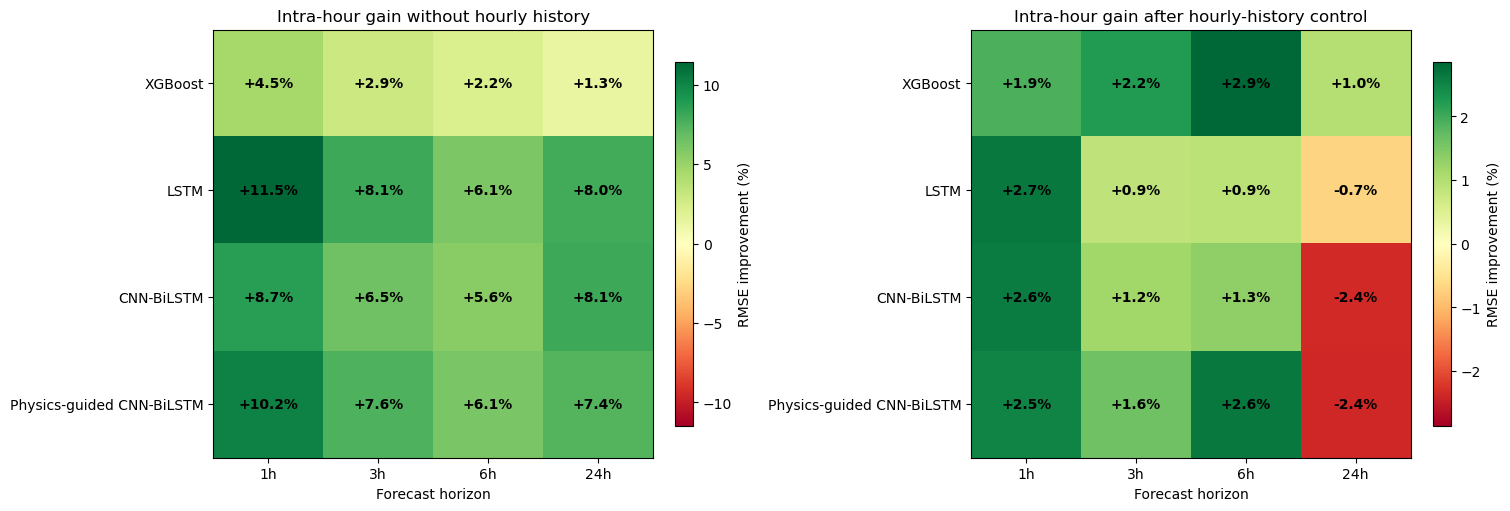

In [19]:
# Separate colour scales keep the two all-procedure contrasts visible.
without_history = comparison["intra_gain_without_history_pct"].unstack(
    "horizon").loc[learned, HORIZONS]
controlled = comparison["controlled_intra_gain_pct"].unstack(
    "horizon").loc[learned, HORIZONS]
panel_limits = [np.nanmax(np.abs(without_history.to_numpy())),
                np.nanmax(np.abs(controlled.to_numpy()))]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax, matrix, title, panel_limit in zip(
        axes, [without_history, controlled],
        ["Intra-hour gain without hourly history",
         "Intra-hour gain after hourly-history control"], panel_limits):
    image = ax.imshow(matrix, cmap="RdYlGn", vmin=-panel_limit,
                      vmax=panel_limit, aspect="auto")
    for row, column in np.ndindex(matrix.shape):
        value = matrix.iloc[row, column]
        if np.isfinite(value):
            ax.text(column, row, f"{value:+.1f}%", ha="center", va="center",
                    fontweight="bold")
    ax.set(xticks=range(len(HORIZONS)), xticklabels=[f"{h}h" for h in HORIZONS],
           yticks=range(len(matrix)), yticklabels=matrix.index,
           xlabel="Forecast horizon", title=title)
    ax.grid(False)
    fig.colorbar(image, ax=ax, label="RMSE improvement (%)", shrink=0.85)
fig.savefig(FIGURES/"feature_ablation_rmse.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

### Reading the feature-ablation figure
The left panel gives the meteorology-only contrast for every learned procedure: `weather` versus `weather_intra`. It asks whether completed-hour variability adds forecast information when ordinary generation history is absent.

The right panel reports the research-question contrast for the same four procedures after ordinary hourly generation history is already present: `weather_history` versus `combined`. Green values favour the added intra-hour inputs. Statistical support is reported in the tables and tests, not inferred from colour alone.

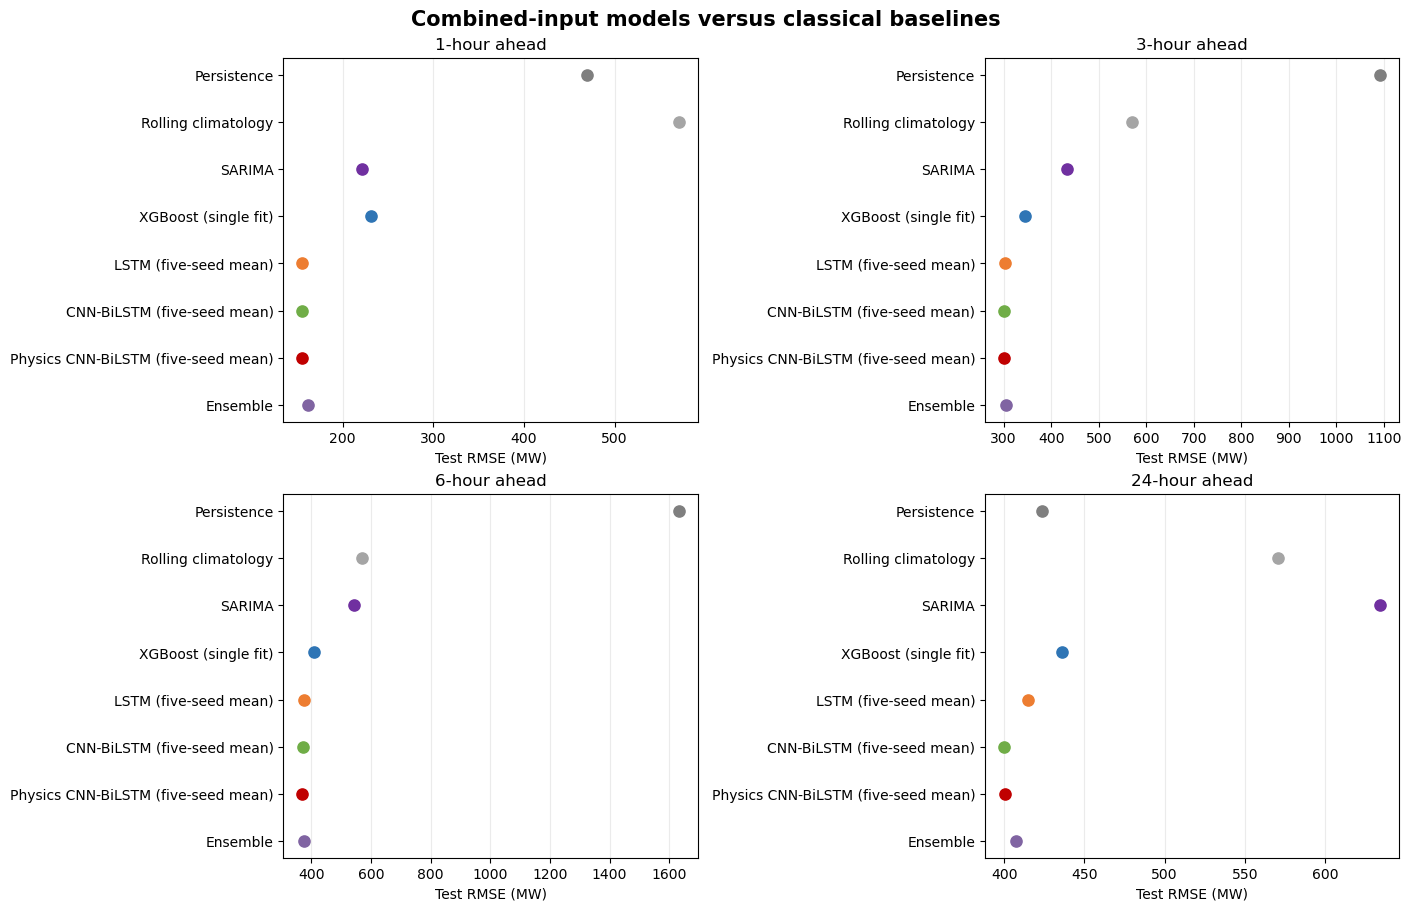

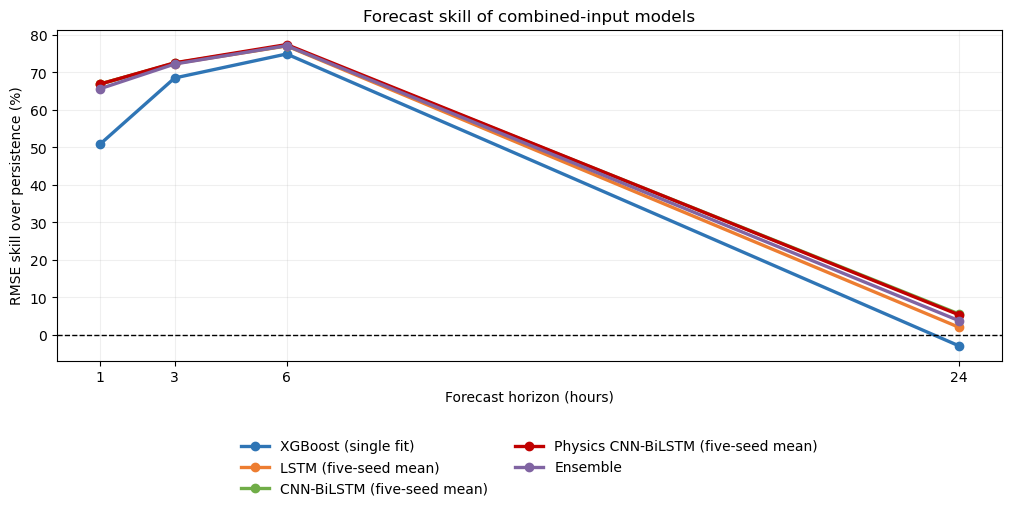

Improvement over each implemented baseline: estimate [95% CI], * stable improvement
Stable improvement requires a positive 168h-block CI and corrected p < .05
under h−1, 24h and 168h DM bandwidths; the ensemble remains descriptive.


baseline                                       Persistence  \
model                     horizon                            
XGBoost                   1        +50.8% [+46.5, +55.6] *   
                          3        +68.5% [+66.8, +70.1] *   
                          6        +74.9% [+73.6, +76.2] *   
                          24           -2.9% [-11.1, +4.7]   
LSTM                      1        +66.9% [+65.2, +68.7] *   
                          3        +72.3% [+71.0, +73.6] *   
                          6        +77.0% [+75.9, +78.0] *   
                          24            +2.1% [-4.4, +8.2]   
CNN-BiLSTM                1        +66.8% [+65.1, +68.7] *   
                          3        +72.5% [+71.2, +73.6] *   
                          6        +77.1% [+76.0, +78.1] *   
                          24           +5.6% [-0.0, +10.8]   
Physics-guided CNN-BiLSTM 1        +66.8% [+65.1, +68.8] *   
                          3        +72.5% [+71.3, +73.7] *   
                          6        +77.4% [+76.3, +78.4] *   
                          24           +5.4% [-0.3, +10.7]   
Ensemble                  1          +65.6% [+63.8, +67.7]   
                          3          +72.2% [+71.0, +73.5]   
                          6          +77.1% [+76.0, +78.1]   
                          24            +3.8% [-2.4, +9.7]   

baseline                               Rolling climatology  \
model                     horizon                            
XGBoost                   1        +59.6% [+56.6, +63.0] *   
                          3        +39.7% [+36.4, +42.8] *   
                          6        +28.2% [+24.0, +31.9] *   
                          24       +23.6% [+19.9, +27.1] *   
LSTM                      1        +72.8% [+70.5, +74.9] *   
                          3        +47.0% [+43.6, +49.8] *   
                          6        +34.3% [+30.1, +37.4] *   
                          24       +27.3% [+23.6, +30.7] *   
CNN-BiLSTM                1        +72.7% [+70.5, +74.8] *   
                          3        +47.3% [+43.7, +50.2] *   
                          6        +34.6% [+30.5, +37.8] *   
                          24       +29.9% [+25.8, +33.6] *   
Physics-guided CNN-BiLSTM 1        +72.8% [+70.5, +74.7] *   
                          3        +47.4% [+43.9, +50.3] *   
                          6        +35.4% [+31.2, +38.7] *   
                          24       +29.7% [+25.7, +33.4] *   
Ensemble                  1          +71.7% [+69.6, +73.8]   
                          3          +46.8% [+43.5, +49.5]   
                          6          +34.6% [+30.6, +37.8]   
                          24         +28.6% [+24.8, +32.1]   

baseline                                            SARIMA  
model                     horizon                           
XGBoost                   1            -4.1% [-14.6, +5.9]  
                          3        +20.5% [+15.7, +25.1] *  
                          6        +24.4% [+20.4, +28.7] *  
                          24       +31.3% [+25.6, +36.7] *  
LSTM                      1        +30.0% [+27.2, +32.8] *  
                          3        +30.2% [+27.0, +33.3] *  
                          6        +30.8% [+27.4, +34.1] *  
                          24       +34.6% [+30.0, +38.9] *  
CNN-BiLSTM                1        +29.8% [+26.8, +32.7] *  
                          3        +30.6% [+27.7, +33.4] *  
                          6        +31.1% [+27.8, +34.4] *  
                          24       +37.0% [+32.8, +40.8] *  
Physics-guided CNN-BiLSTM 1        +29.8% [+26.9, +32.7] *  
                          3        +30.7% [+27.9, +33.5] *  
                          6        +32.0% [+28.7, +35.1] *  
                          24       +36.8% [+32.6, +40.7] *  
Ensemble                  1          +27.2% [+23.6, +30.8]  
                          3          +29.9% [+26.8, +33.1]  
                          6          +31.1% [+27.7

Worst corrected p-value across baseline-test bandwidths:


,model,horizon,baseline,worst_adjusted_p,robust_improvement
0,XGBoost,1,Persistence,<.0001,True
1,XGBoost,1,Rolling climatology,<.0001,True
2,XGBoost,1,SARIMA,1.0000,False
3,XGBoost,3,Persistence,<.0001,True
4,XGBoost,3,Rolling climatology,<.0001,True
5,XGBoost,3,SARIMA,<.0001,True
6,XGBoost,6,Persistence,<.0001,True
7,XGBoost,6,Rolling climatology,<.0001,True
8,XGBoost,6,SARIMA,<.0001,True
9,XGBoost,24,Persistence,1.0000,False


In [20]:
baseline_names = ["Persistence", "Rolling climatology", "SARIMA"]
comparison_models = learned+["Ensemble"]
evaluation_colours = {"Persistence": "#7F7F7F",
                      "Rolling climatology": "#A5A5A5",
                      "SARIMA": "#7030A0", "XGBoost": "#2F75B5",
                      "LSTM": "#ED7D31",
                      "CNN-BiLSTM": "#70AD47",
                      "Physics-guided CNN-BiLSTM": "#C00000",
                      "Ensemble": "#8064A2"}
combined_metrics = results.loc[results.feature_set.eq("combined")].pivot(
    index="horizon", columns="model", values="RMSE_MW").loc[HORIZONS]


# Per-horizon dot plots avoid compressing learned models under large baseline errors.
display_order = baseline_names+comparison_models
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
for h, ax in zip(HORIZONS, axes.flat):
    for row, name in enumerate(display_order):
        ax.scatter(combined_metrics.loc[h, name], row, s=65,
                   color=evaluation_colours[name], zorder=3)
    ax.set(title=f"{h}-hour ahead", xlabel="Test RMSE (MW)",
           yticks=range(len(display_order)),
           yticklabels=[procedure_label.get(name, name)
                       for name in display_order])
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)
fig.suptitle("Combined-input models versus classical baselines",
             fontsize=15, fontweight="bold")
fig.savefig(FIGURES/"baseline_comparison_rmse.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

# Persistence skill above zero indicates lower RMSE than persistence.
skill = results.loc[results.feature_set.eq("combined") &
                    results.model.isin(comparison_models)].pivot(
    index="horizon", columns="model",
    values="skill_persistence_pct").loc[HORIZONS, comparison_models]
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for name in comparison_models:
    ax.plot(HORIZONS, skill[name], marker="o", linewidth=2.4,
            color=evaluation_colours[name],
            label=procedure_label.get(name, name))
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set(xticks=HORIZONS, xlabel="Forecast horizon (hours)",
       ylabel="RMSE skill over persistence (%)",
       title="Forecast skill of combined-input models")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20),
          frameon=False, ncol=2)
fig.savefig(FIGURES/"forecast_skill_by_model.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()


# Baseline tests use separate 48-test families for each dependence bandwidth.
baseline_dm_rows = []
for bandwidth_rule in ["h-1", "24h", "168h"]:
    for name in learned:
        for h in HORIZONS:
            block = blocks["combined", h]
            actual = block["test"]["y"]
            lag = h-1 if bandwidth_rule == "h-1" else int(bandwidth_rule[:-1])
            for baseline in baseline_names:
                statistic, p_value = dm_test(
                    predictions["combined", h][baseline]-actual,
                    predictions["combined", h][name]-actual, lag)
                baseline_dm_rows.append({"bandwidth": bandwidth_rule,
                    "model": name, "horizon": h, "baseline": baseline,
                    "DM_stat": statistic, "p_raw": p_value})
baseline_dm = pd.DataFrame(baseline_dm_rows)
baseline_dm["p_bonferroni"] = baseline_dm.groupby("bandwidth").p_raw.transform(
    lambda values: np.minimum(values*len(values), 1))
baseline_p_worst = baseline_dm.groupby(
    ["model", "horizon", "baseline"]).p_bonferroni.max()

baseline_rows = []
for name in comparison_models:
    for h in HORIZONS:
        block = blocks["combined", h]
        actual = block["test"]["y"]
        candidate = predictions["combined", h][name]
        for baseline in baseline_names:
            reference = predictions["combined", h][baseline]
            gain = 100*(rmse(actual, reference)-rmse(actual, candidate))/rmse(
                actual, reference)
            low, high = moving_block_gain_interval(
                actual, reference, candidate, block["test"]["target_time"], 168)
            p_worst = (baseline_p_worst.get((name, h, baseline), np.nan)
                       if name in learned else np.nan)
            robust = bool(gain > 0 and low > 0 and p_worst < 0.05)
            baseline_rows.append({"model": name, "horizon": h,
                "baseline": baseline, "improvement_pct": gain,
                "CI_low": low, "CI_high": high,
                "worst_adjusted_p": p_worst,
                "robust_improvement": robust})
baseline_improvement = pd.DataFrame(baseline_rows)
baseline_improvement["summary"] = baseline_improvement.apply(
    lambda row: (f"{row.improvement_pct:+.1f}% "
                 f"[{row.CI_low:+.1f}, {row.CI_high:+.1f}]"
                 f"{' *' if row.robust_improvement else ''}"), axis=1)
table_order = pd.MultiIndex.from_product(
    [comparison_models, HORIZONS], names=["model", "horizon"])
baseline_improvement_table = baseline_improvement.pivot(
    index=["model", "horizon"], columns="baseline",
    values="summary").reindex(index=table_order, columns=baseline_names)
print("Improvement over each implemented baseline: estimate [95% CI], * stable improvement")
print("Stable improvement requires a positive 168h-block CI and corrected p < .05")
print("under h−1, 24h and 168h DM bandwidths; the ensemble remains descriptive.")
display(baseline_improvement_table)
print("Worst corrected p-value across baseline-test bandwidths:")
# Format the p-value column without changing the numeric test table.
baseline_p_display = baseline_improvement.loc[
    baseline_improvement.model.isin(learned),
    ["model", "horizon", "baseline", "worst_adjusted_p",
     "robust_improvement"]].copy()
baseline_p_display["worst_adjusted_p"] = (
    baseline_p_display.worst_adjusted_p.map(format_p_value))
display(baseline_p_display)

### Reading the baseline comparison
Each horizon has its own RMSE panel so large baseline errors do not flatten differences among the learned procedures. The skill curve uses persistence as zero: values above zero mean lower RMSE than persistence.

Point estimates answer how large the improvement is. The paired 168-hour block interval and three corrected Diebold-Mariano bandwidths determine whether the notebook labels a learned procedure as better than one of the three implemented baselines. The ensemble is shown but remains outside the significance family.

### 11.1 Secondary comparison among learned forecasting procedures
These paired comparisons use the common `combined` information set. Each bandwidth defines a 24-test family: six procedure pairs at four horizons. The neural procedures are five-seed forecast means, whereas XGBoost is a single fitted model. A winner is reported only when the 168-hour moving-block interval excludes zero and all three corrected Diebold-Mariano analyses agree on direction and significance.

The CNN-BiLSTM versus physics-guided CNN-BiLSTM comparison isolates the tested loss penalties because architecture, inputs, optimiser and seeds are matched. All other pairs compare forecasting procedures rather than individual architecture components or training-seed uncertainty. The secondary validation-weighted ensemble is excluded because it is derived from the four procedures being compared.

,reference,candidate,horizon,candidate_gain_pct,CI_low,CI_high,worst_adjusted_p,robust_winner
0,XGBoost,LSTM,1,32.705,26.833,37.743,<.0001,LSTM
1,XGBoost,LSTM,3,12.145,9.180,14.923,<.0001,LSTM
2,XGBoost,LSTM,6,8.485,5.511,10.633,<.0001,LSTM
3,XGBoost,LSTM,24,4.809,1.901,7.442,0.0811,No robust difference
4,XGBoost,CNN-BiLSTM,1,32.560,26.970,37.264,<.0001,CNN-BiLSTM
5,XGBoost,CNN-BiLSTM,3,12.648,9.167,15.896,<.0001,CNN-BiLSTM
6,XGBoost,CNN-BiLSTM,6,8.902,5.783,11.270,<.0001,CNN-BiLSTM
7,XGBoost,CNN-BiLSTM,24,8.270,5.030,11.220,0.0008,CNN-BiLSTM
8,XGBoost,Physics-guided CNN-BiLSTM,1,32.584,27.012,37.224,<.0001,Physics-guided CNN-BiLSTM
9,XGBoost,Physics-guided CNN-BiLSTM,3,12.833,9.399,15.993,<.0001,Physics-guided CNN-BiLSTM


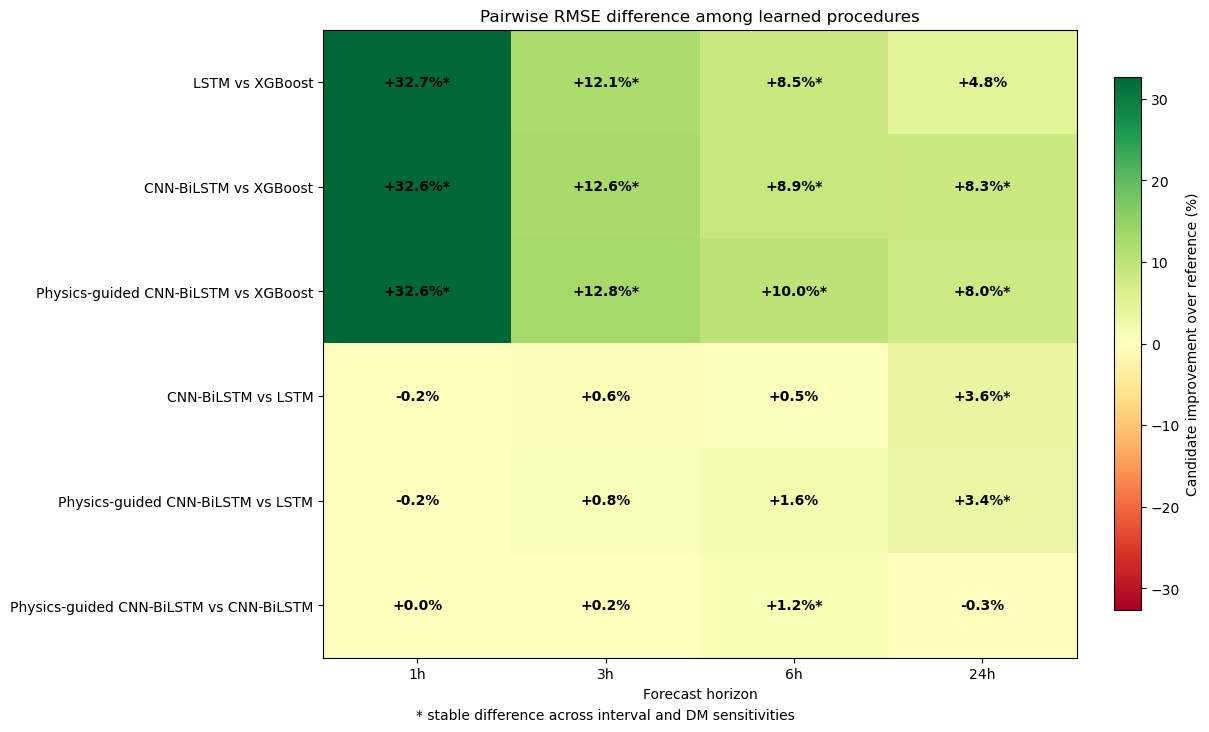

In [21]:
# A separate corrected family supports secondary procedure comparison.
learned_pairs = [
    ("XGBoost", "LSTM"),
    ("XGBoost", "CNN-BiLSTM"),
    ("XGBoost", "Physics-guided CNN-BiLSTM"),
    ("LSTM", "CNN-BiLSTM"),
    ("LSTM", "Physics-guided CNN-BiLSTM"),
    ("CNN-BiLSTM", "Physics-guided CNN-BiLSTM")]

pairwise_dm_rows = []
for bandwidth_rule in ["h-1", "24h", "168h"]:
    for reference_model, candidate_model in learned_pairs:
        for h in HORIZONS:
            block = blocks["combined", h]
            actual = block["test"]["y"]
            lag = h-1 if bandwidth_rule == "h-1" else int(bandwidth_rule[:-1])
            statistic, p_value = dm_test(
                predictions["combined", h][reference_model]-actual,
                predictions["combined", h][candidate_model]-actual, lag)
            pairwise_dm_rows.append({"bandwidth": bandwidth_rule,
                "reference": reference_model, "candidate": candidate_model,
                "horizon": h, "DM_stat": statistic, "p_raw": p_value})
pairwise_dm = pd.DataFrame(pairwise_dm_rows)
pairwise_dm["p_bonferroni"] = pairwise_dm.groupby("bandwidth").p_raw.transform(
    lambda values: np.minimum(values*len(values), 1))

pairwise_rows = []
for reference_model, candidate_model in learned_pairs:
    for h in HORIZONS:
        block = blocks["combined", h]
        actual = block["test"]["y"]
        reference = predictions["combined", h][reference_model]
        candidate = predictions["combined", h][candidate_model]
        gain = 100*(rmse(actual, reference)-rmse(actual, candidate))/rmse(
            actual, reference)
        low, high = moving_block_gain_interval(
            actual, reference, candidate, block["test"]["target_time"], 168)
        tests = pairwise_dm.loc[
            pairwise_dm.reference.eq(reference_model) &
            pairwise_dm.candidate.eq(candidate_model) &
            pairwise_dm.horizon.eq(h)]
        all_significant = tests.p_bonferroni.lt(0.05).all()
        direction_agrees = (np.sign(tests.DM_stat) == np.sign(gain)).all()
        interval_excludes_zero = low > 0 or high < 0
        robust = bool(all_significant and direction_agrees and interval_excludes_zero)
        winner = (candidate_model if robust and gain > 0 else
                  reference_model if robust and gain < 0 else
                  "No robust difference")
        pairwise_rows.append({"reference": reference_model,
            "candidate": candidate_model, "horizon": h,
            "candidate_gain_pct": gain, "CI_low": low, "CI_high": high,
            "worst_adjusted_p": tests.p_bonferroni.max(),
            "robust_winner": winner})
pairwise_results = pd.DataFrame(pairwise_rows)
# Keep p-values readable while leaving effect estimates numeric.
pairwise_display = pairwise_results.round(3).copy()
pairwise_display["worst_adjusted_p"] = (
    pairwise_results.worst_adjusted_p.map(format_p_value))
display(pairwise_display)

pair_labels = [f"{candidate} vs {reference}"
               for reference, candidate in learned_pairs]
gain_matrix = pairwise_results.assign(
    pair=pairwise_results.candidate+" vs "+pairwise_results.reference).pivot(
        index="pair", columns="horizon", values="candidate_gain_pct").reindex(
            index=pair_labels, columns=HORIZONS)
winner_lookup = pairwise_results.set_index(
    ["candidate", "reference", "horizon"]).robust_winner
colour_limit = max(1, np.nanmax(np.abs(gain_matrix.to_numpy())))
fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
image = ax.imshow(gain_matrix, cmap="RdYlGn", vmin=-colour_limit,
                  vmax=colour_limit, aspect="auto")
for row, (reference, candidate) in enumerate(learned_pairs):
    for column, h in enumerate(HORIZONS):
        value = gain_matrix.loc[f"{candidate} vs {reference}", h]
        winner = winner_lookup.loc[(candidate, reference, h)]
        marker = "*" if winner != "No robust difference" else ""
        ax.text(column, row, f"{value:+.1f}%{marker}",
                ha="center", va="center", fontweight="bold")
ax.set(xticks=range(len(HORIZONS)),
       xticklabels=[f"{h}h" for h in HORIZONS],
       yticks=range(len(pair_labels)), yticklabels=pair_labels,
       xlabel="Forecast horizon",
       title="Pairwise RMSE difference among learned procedures")
ax.grid(False)
fig.colorbar(image, ax=ax,
             label="Candidate improvement over reference (%)", shrink=0.85)
fig.text(0.5, -0.02, "* stable difference across interval and DM sensitivities",
         ha="center")
fig.savefig(FIGURES/"pairwise_model_superiority.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

### 11.2 Secondary post-model exploratory diagnostics
Daylight RMSE removes the easy nighttime zeros. Mean bias shows whether a model tends to forecast above or below the observed output. Weather-regime RMSE tests whether the ordering changes between overcast, variable and clear hours.

These plots explain patterns already present in the error results. They are not extra significance tests.

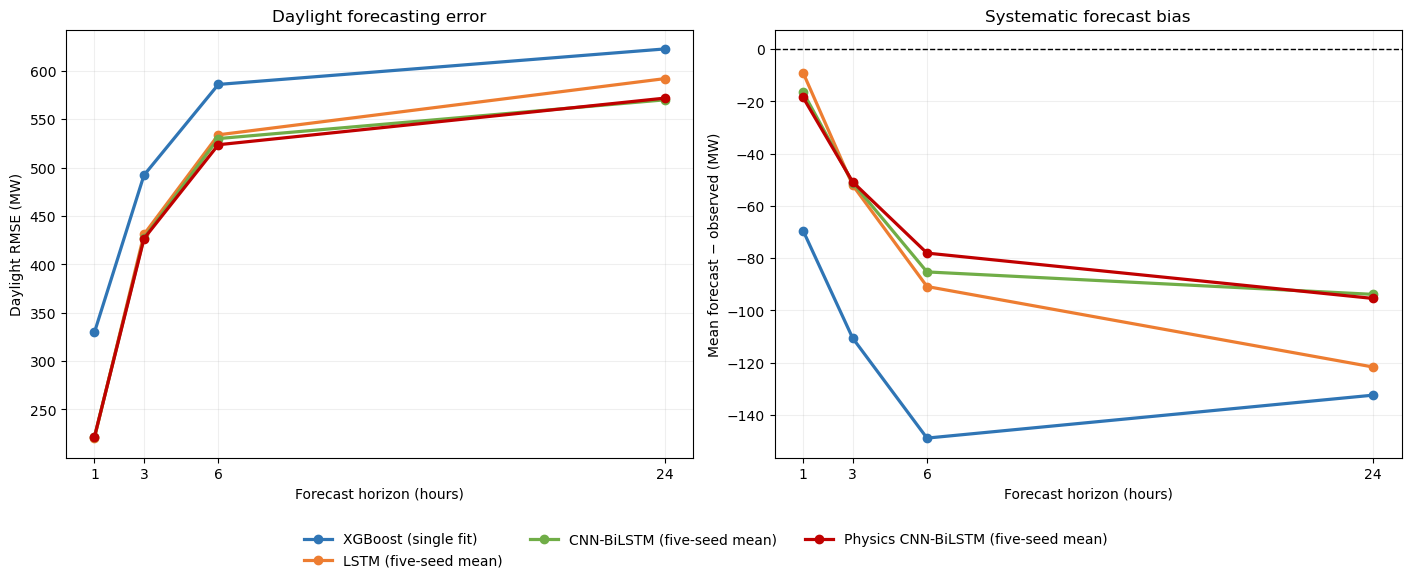

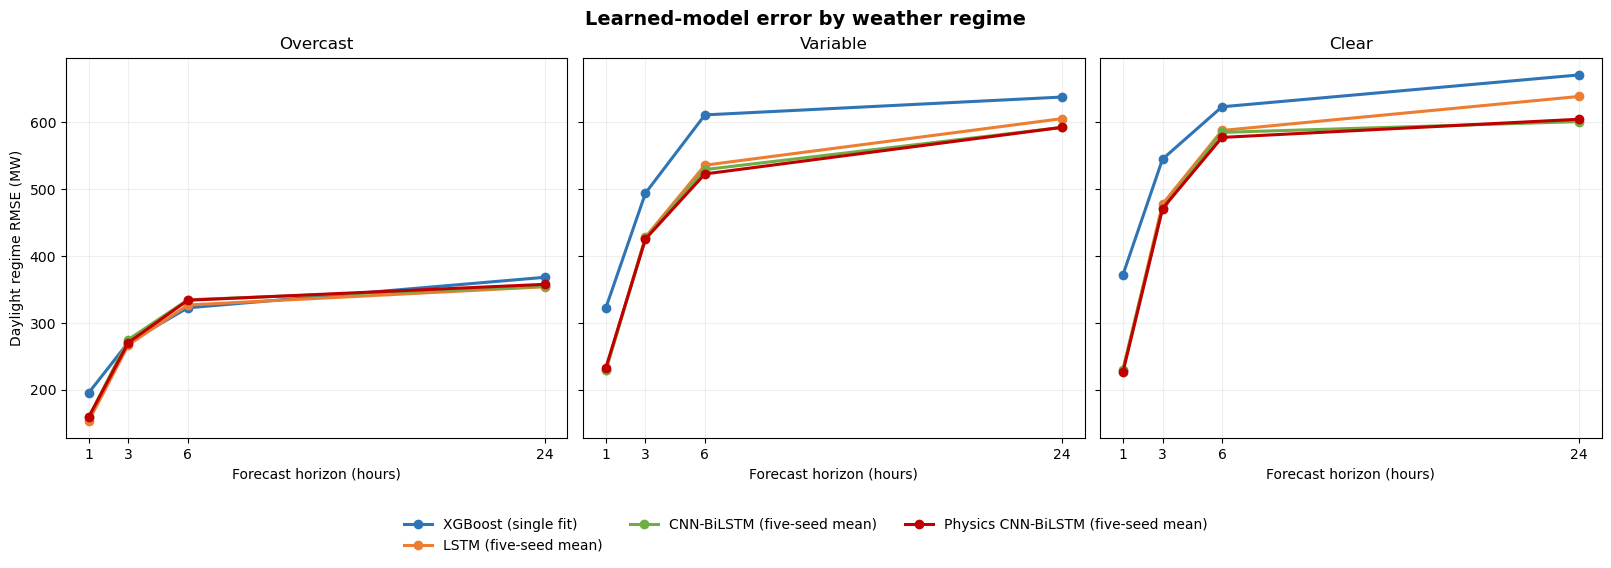

In [22]:
# Daylight error and bias explain differences hidden by aggregate RMSE.
diagnostic_metrics = results.loc[
    results.feature_set.eq("combined") & results.model.isin(learned)]
daylight_matrix = diagnostic_metrics.pivot(
    index="horizon", columns="model", values="daylight_RMSE").loc[
        HORIZONS, learned]
bias_matrix = diagnostic_metrics.pivot(
    index="horizon", columns="model", values="bias_MW").loc[
        HORIZONS, learned]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for name in learned:
    axes[0].plot(HORIZONS, daylight_matrix[name], marker="o", linewidth=2.3,
                 color=evaluation_colours[name],
                 label=procedure_label.get(name, name))
    axes[1].plot(HORIZONS, bias_matrix[name], marker="o", linewidth=2.3,
                 color=evaluation_colours[name],
                 label=procedure_label.get(name, name))
axes[0].set(title="Daylight forecasting error", xlabel="Forecast horizon (hours)",
            ylabel="Daylight RMSE (MW)", xticks=HORIZONS)
axes[1].axhline(0, color="black", linewidth=1, linestyle="--")
axes[1].set(title="Systematic forecast bias", xlabel="Forecast horizon (hours)",
            ylabel="Mean forecast − observed (MW)", xticks=HORIZONS)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.03),
           ncol=3, frameon=False)
fig.savefig(FIGURES/"learned_model_error_diagnostics.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

learned_regimes = regime_results.loc[regime_results.model.isin(learned)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True,
                         constrained_layout=True)
for ax, regime in zip(axes, ["Overcast", "Variable", "Clear"]):
    subset = learned_regimes.loc[learned_regimes.regime.eq(regime)]
    for name in learned:
        values = subset.loc[subset.model.eq(name)].set_index("horizon").loc[HORIZONS]
        ax.plot(HORIZONS, values.combined_RMSE, marker="o", linewidth=2.2,
                color=evaluation_colours[name],
                label=procedure_label.get(name, name))
    ax.set(title=regime, xlabel="Forecast horizon (hours)", xticks=HORIZONS)
axes[0].set_ylabel("Daylight regime RMSE (MW)")
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Learned-model error by weather regime",
             fontsize=14, fontweight="bold")
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.04),
           ncol=3, frameon=False)
fig.savefig(FIGURES/"learned_model_weather_regimes.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

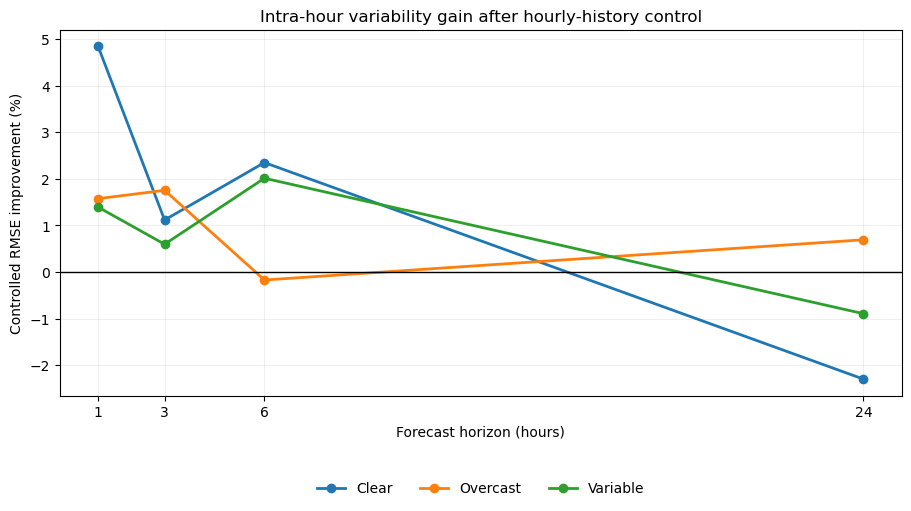

In [23]:
# The ensemble regime plot is descriptive and excluded from hypothesis tests.
ensemble_regime = regime_results.loc[regime_results.model.eq("Ensemble")]
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
for regime, values in ensemble_regime.groupby("regime"):
    values = values.set_index("horizon").loc[HORIZONS]
    ax.plot(HORIZONS, values.gain_pct, marker="o", linewidth=2, label=regime)
ax.axhline(0, color="black", linewidth=1)
ax.set(xticks=HORIZONS, xlabel="Forecast horizon (hours)",
       ylabel="Controlled RMSE improvement (%)",
       title="Intra-hour variability gain after hourly-history control")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20),
          ncol=3, frameon=False)
fig.savefig(FIGURES/"weather_regime_gain.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

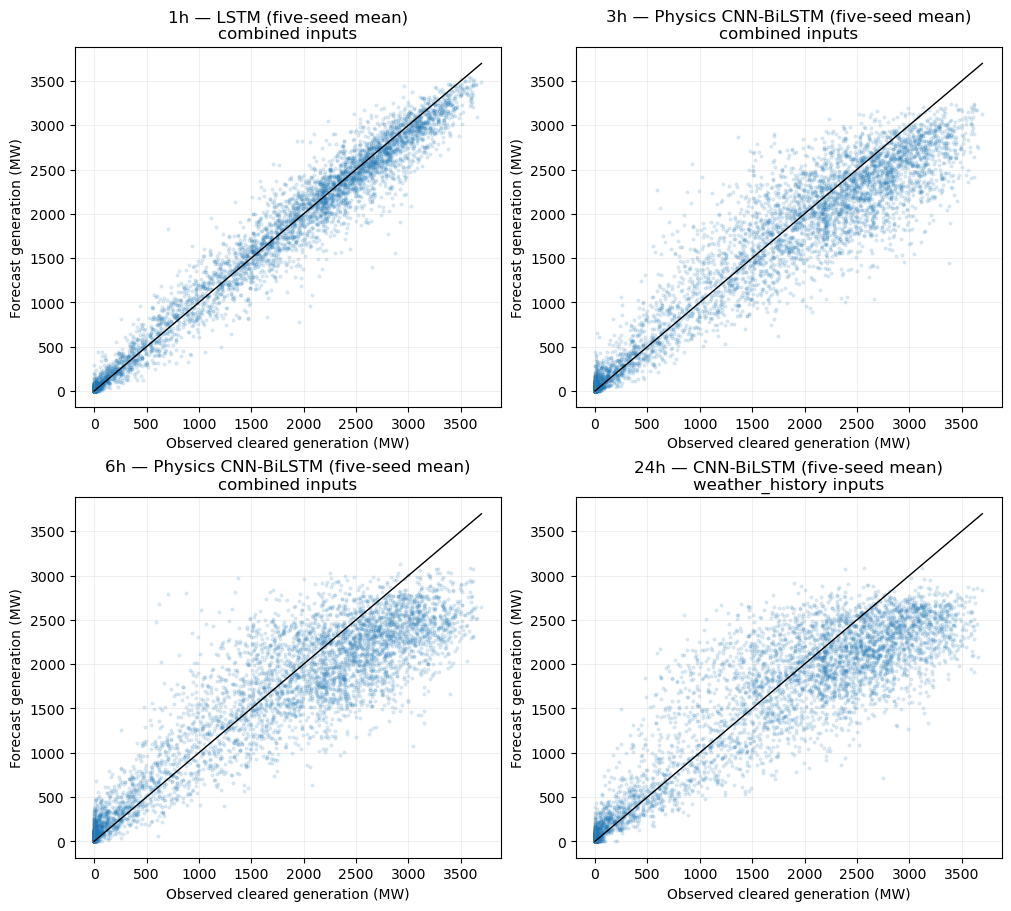

In [24]:
# Calibration panels use the lowest-RMSE learned forecast per horizon, chosen
# across all feature sets, so the selected inputs can differ by horizon.
fig, axes = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True)
for h, ax in zip(HORIZONS, axes.flat):
    candidates = results.loc[results.horizon.eq(h) & results.model.isin(learned)]
    best = candidates.sort_values("RMSE_MW").iloc[0]
    block = blocks[best.feature_set, h]
    actual = block["test"]["y"]
    forecast = predictions[best.feature_set, h][best.model]
    limit = max(actual.max(), forecast.max())
    ax.scatter(actual, forecast, s=4, alpha=0.12)
    ax.plot([0, limit], [0, limit], color="black", linewidth=1)
    ax.set(title=f"{h}h — {procedure_label[best.model]}\n{best.feature_set} inputs",
           xlabel="Observed cleared generation (MW)",
           ylabel="Forecast generation (MW)")
fig.savefig(FIGURES / "actual_vs_predicted_test.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()


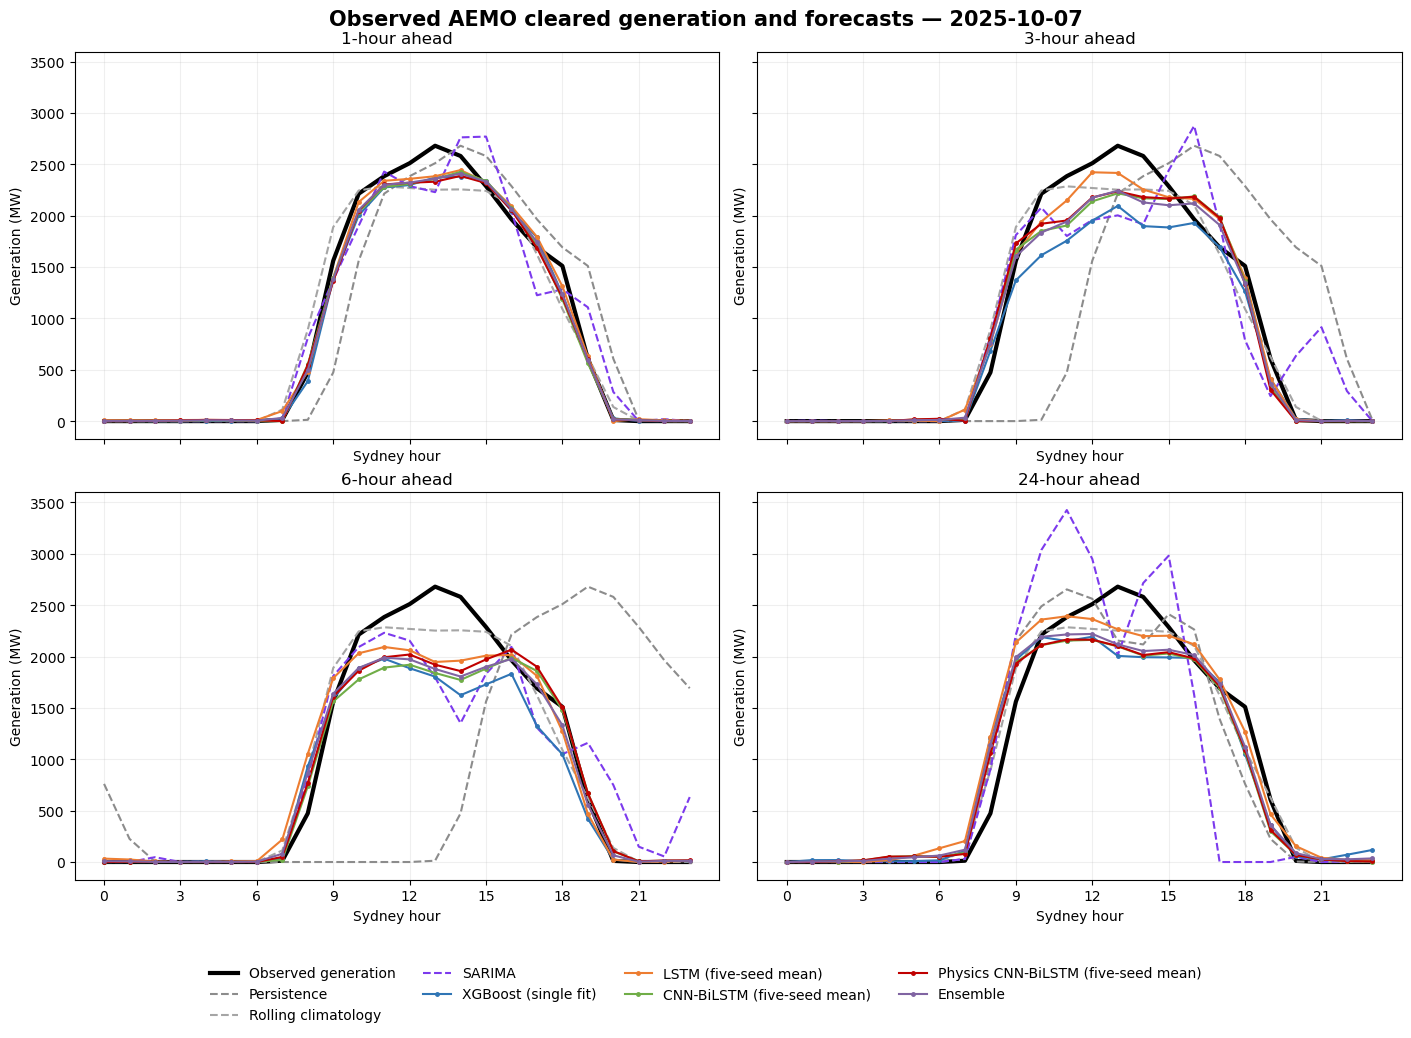

In [25]:
# Select a typical day from observed energy only, not forecast accuracy.
reference = blocks["combined", 24]
reference_time = reference["test"]["target_time"]
reference_actual = reference["test"]["y"]
daily = pd.Series(reference_actual, index=reference_time).groupby(
    reference_time.normalize()).agg(["count", "sum"])
daily = daily.loc[daily["count"].eq(24)]
representative_day = (daily["sum"]-daily["sum"].median()).abs().idxmin()

colours = {"Persistence": "#8C8C8C", "Rolling climatology": "#A5A5A5",
           "SARIMA": "#7C3AED", "XGBoost": "#2F75B5", "LSTM": "#ED7D31",
           "CNN-BiLSTM": "#70AD47",
           "Physics-guided CNN-BiLSTM": "#C00000", "Ensemble": "#8064A2"}
display_models = ["Persistence", "Rolling climatology", "SARIMA"]+models
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True,
                         constrained_layout=True)
for h, ax in zip(HORIZONS, axes.flat):
    block = blocks["combined", h]
    target_time = block["test"]["target_time"]
    mask = target_time.normalize() == representative_day
    assert mask.sum() == 24
    hours = target_time[mask].hour
    ax.plot(hours, block["test"]["y"][mask], color="black", linewidth=3,
            label="Observed generation")
    for name in display_models:
        baseline = name in ["Persistence", "Rolling climatology", "SARIMA"]
        ax.plot(hours, predictions["combined", h][name][mask], color=colours[name],
                linestyle="--" if baseline else "-", marker=None if baseline else "o",
                markersize=2.5, linewidth=1.5,
                label=procedure_label.get(name, name))
    ax.set_title(f"{h}-hour ahead")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Sydney hour")
    ax.set_ylabel("Generation (MW)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle(f"Observed AEMO cleared generation and forecasts — {representative_day.date()}",
             fontsize=15, fontweight="bold", y=1.02)
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.03),
           ncol=4, frameon=False)
fig.savefig(FIGURES/"all_models_observed_by_horizon.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

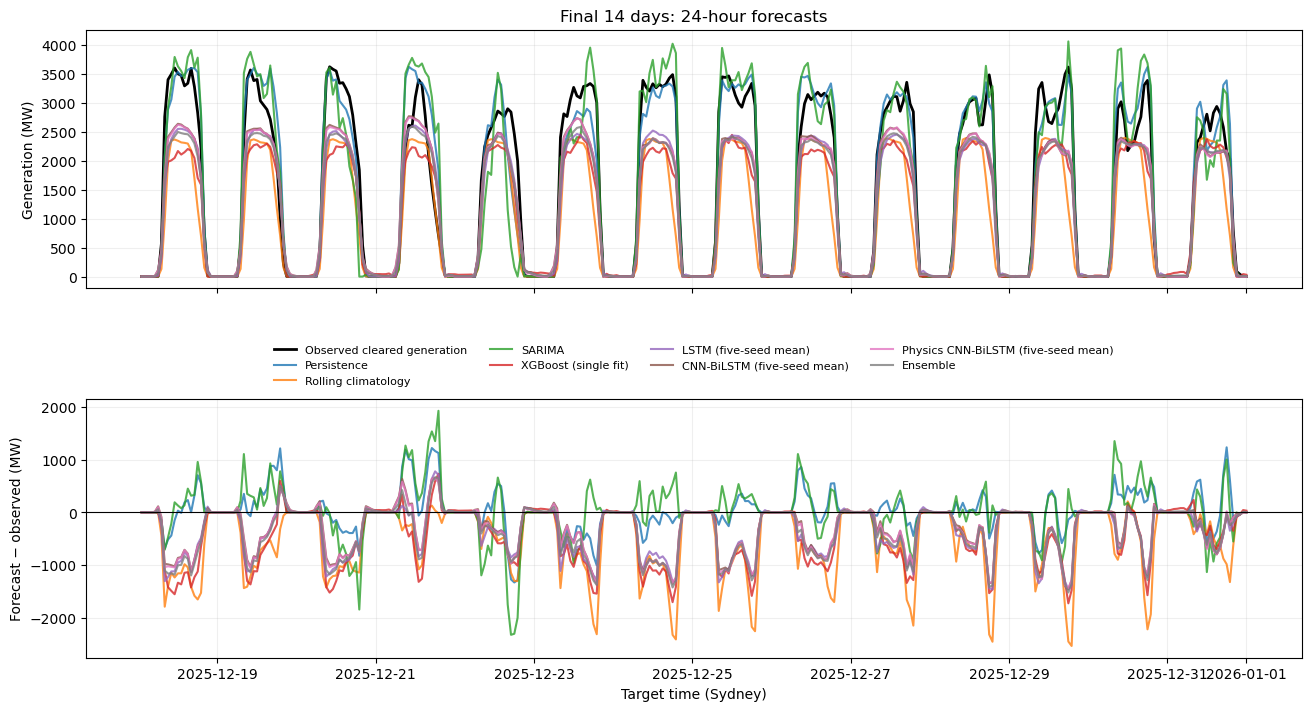

In [26]:
# Inspect two weeks of day-ahead trajectories and signed residuals.
h = 24
feature_set = "combined"
block = blocks[feature_set, h]
time = block["test"]["target_time"]
actual = block["test"]["y"]
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
axes[0].plot(time[-336:], actual[-336:], color="black", linewidth=2,
             label="Observed cleared generation")
for name in display_models:
    pred = predictions[feature_set, h][name]
    axes[0].plot(time[-336:], pred[-336:], alpha=0.8,
                 label=procedure_label.get(name, name))
    axes[1].plot(time[-336:], (pred-actual)[-336:], alpha=0.8)
axes[0].set_title("Final 14 days: 24-hour forecasts")
axes[0].set_ylabel("Generation (MW)")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18),
               ncol=4, fontsize=8, frameon=False)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Forecast − observed (MW)")
axes[1].set_xlabel("Target time (Sydney)")
plt.show()

### 11.3 Day-ahead residual checks
The final 14-day panel keeps time order visible and places signed errors directly below the forecasts. It can reveal missed peaks, timing errors or periods when several models fail together. Monthly mean residuals then test whether over- or under-forecasting persists across seasons.

These are diagnostic views. They do not replace the full-year RMSE or paired tests.

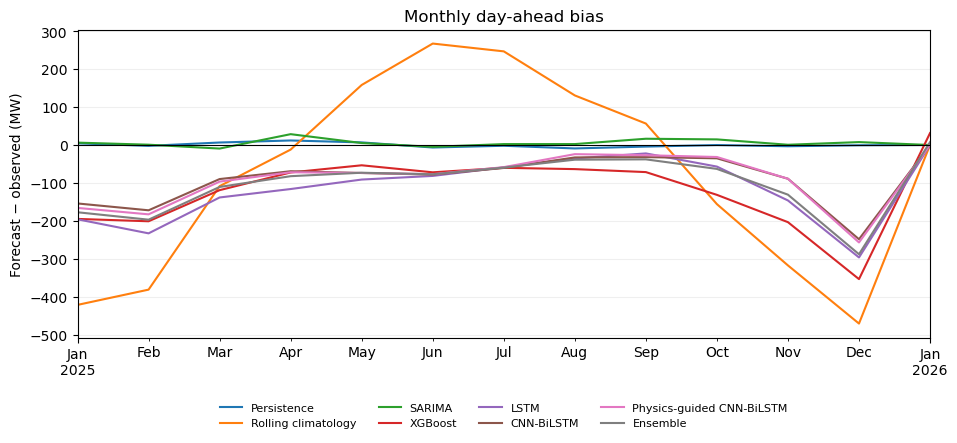

In [27]:
# Monthly mean residuals reveal persistent seasonal bias.
monthly = pd.DataFrame({name: pd.Series(pred-actual, index=time).resample("MS").mean()
                        for name, pred in predictions["combined", 24].items()})
monthly.plot(title="Monthly day-ahead bias",
             ylabel="Forecast − observed (MW)", figsize=(11, 4))
plt.axhline(0, color="black", linewidth=0.8)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18),
           ncol=4, fontsize=8, frameon=False)
plt.show()


### 11.4 Evidence-based interpretation
This summary is generated from the current results rather than typed by hand. It reports the lowest combined-input RMSE at each horizon, counts baseline comparisons that pass every sensitivity check, and states both intra-hour contrasts for each learned procedure.

In this section, "stable" means that the paired interval and every specified dependence-sensitive corrected test agree. For each intra-hour result, the output-scale-relative error must also agree in direction with the raw-MW result.

In [28]:
# Build conclusions from current tables so prose cannot retain stale values.
interpretation = ["**Model performance.**"]
for h in HORIZONS:
    candidates = results.loc[
        results.feature_set.eq("combined") &
        results.horizon.eq(h) & results.model.isin(learned)]
    best = candidates.sort_values("RMSE_MW").iloc[0]
    interpretation.append(
        f"- At {h}h, **{procedure_label[best.model]}** had the lowest "
        f"combined-input RMSE "
        f"({best.RMSE_MW:.2f} MW; {best.nRMSE_peak_pct:.2f}% of test peak; "
        f"daylight RMSE {best.daylight_RMSE:.2f} MW).")

interpretation.append("\n**Stable improvement over the implemented classical baselines.**")
for name in learned:
    count = int(baseline_improvement.loc[
        baseline_improvement.model.eq(name), "robust_improvement"].sum())
    interpretation.append(
        f"- **{name}:** {count}/12 model–horizon–baseline comparisons.")

interpretation.append("\n**Secondary forecasting-procedure comparisons.**")
for row in pairwise_results.itertuples():
    winner_label = procedure_label.get(row.robust_winner, row.robust_winner)
    interpretation.append(
        f"- {row.horizon}h, {procedure_label[row.candidate]} versus "
        f"{procedure_label[row.reference]}: "
        f"{row.candidate_gain_pct:+.2f}% RMSE difference "
        f"[{row.CI_low:+.2f}, {row.CI_high:+.2f}]; "
        f"**{winner_label}**.")

def summarise_intra_hour(comparison_name, gain_column):
    rows = []
    for name in learned:
        for h in HORIZONS:
            interval = interval_results.loc[
                interval_results.comparison.eq(comparison_name) &
                interval_results.model.eq(name) &
                interval_results.horizon.eq(h) &
                interval_results.block_hours.eq(168)].iloc[0]
            tests = dm_results.loc[
                dm_results.comparison.eq(comparison_name) &
                dm_results.model.eq(name) & dm_results.horizon.eq(h)]
            assert len(tests) == 3
            direction_agrees = (np.sign(tests.DM_stat) == -np.sign(
                interval.gain_pct)).all()
            # Require the scale-normalised result to keep the raw-MW direction.
            relative_gain = relative.loc[(name, h), gain_column]
            scale_direction_agrees = np.sign(relative_gain) == np.sign(
                interval.gain_pct)
            robust = (tests.p_bonferroni.lt(0.05).all() and direction_agrees and
                      scale_direction_agrees and
                      (interval.CI_low > 0 or interval.CI_high < 0))
            finding = ("robust gain" if robust and interval.gain_pct > 0 else
                       "robust deterioration" if robust else "inconclusive")
            rows.append({"model": name, "horizon": h,
                "gain_pct": interval.gain_pct, "CI_low": interval.CI_low,
                "CI_high": interval.CI_high,
                "output_scale_gain_pct": relative_gain,
                "output_scale_agrees": scale_direction_agrees,
                "finding": finding})
    return pd.DataFrame(rows)

without_history_summary = summarise_intra_hour(
    "Intra-hour addition without history",
    "intra_gain_without_history_pct")
controlled_summary = summarise_intra_hour(
    "Controlled intra-hour addition", "controlled_intra_gain_pct")
interpretation.append(
    "\n**Interpretive boundary.** These are predictive associations for the "
    "repeatedly inspected 2025 evaluation year. Neural labels denote "
    "five-seed mean forecasts, while XGBoost is a single fit. The comparisons "
    "use a matched control to isolate the tested physical loss penalties, "
    "but do not isolate the other architecture components, training-seed uncertainty or "
    "operational performance with forecast-weather inputs.")
display(Markdown("\n".join(interpretation)))
print("Intra-hour evidence without hourly history:")
display(without_history_summary.round(2))
print("Controlled intra-hour evidence after hourly history:")
display(controlled_summary.round(2))


**Model performance.**
- At 1h, **LSTM (five-seed mean)** had the lowest combined-input RMSE (155.25 MW; 4.20% of test peak; daylight RMSE 220.43 MW).
- At 3h, **Physics CNN-BiLSTM (five-seed mean)** had the lowest combined-input RMSE (300.28 MW; 8.12% of test peak; daylight RMSE 426.52 MW).
- At 6h, **Physics CNN-BiLSTM (five-seed mean)** had the lowest combined-input RMSE (369.17 MW; 9.99% of test peak; daylight RMSE 523.53 MW).
- At 24h, **CNN-BiLSTM (five-seed mean)** had the lowest combined-input RMSE (399.77 MW; 10.81% of test peak; daylight RMSE 569.90 MW).

**Stable improvement over the implemented classical baselines.**
- **XGBoost:** 10/12 model–horizon–baseline comparisons.
- **LSTM:** 11/12 model–horizon–baseline comparisons.
- **CNN-BiLSTM:** 11/12 model–horizon–baseline comparisons.
- **Physics-guided CNN-BiLSTM:** 11/12 model–horizon–baseline comparisons.

**Secondary forecasting-procedure comparisons.**
- 1h, LSTM (five-seed mean) versus XGBoost (single fit): +32.71% RMSE difference [+26.83, +37.74]; **LSTM (five-seed mean)**.
- 3h, LSTM (five-seed mean) versus XGBoost (single fit): +12.15% RMSE difference [+9.18, +14.92]; **LSTM (five-seed mean)**.
- 6h, LSTM (five-seed mean) versus XGBoost (single fit): +8.48% RMSE difference [+5.51, +10.63]; **LSTM (five-seed mean)**.
- 24h, LSTM (five-seed mean) versus XGBoost (single fit): +4.81% RMSE difference [+1.90, +7.44]; **No robust difference**.
- 1h, CNN-BiLSTM (five-seed mean) versus XGBoost (single fit): +32.56% RMSE difference [+26.97, +37.26]; **CNN-BiLSTM (five-seed mean)**.
- 3h, CNN-BiLSTM (five-seed mean) versus XGBoost (single fit): +12.65% RMSE difference [+9.17, +15.90]; **CNN-BiLSTM (five-seed mean)**.
- 6h, CNN-BiLSTM (five-seed mean) versus XGBoost (single fit): +8.90% RMSE difference [+5.78, +11.27]; **CNN-BiLSTM (five-seed mean)**.
- 24h, CNN-BiLSTM (five-seed mean) versus XGBoost (single fit): +8.27% RMSE difference [+5.03, +11.22]; **CNN-BiLSTM (five-seed mean)**.
- 1h, Physics CNN-BiLSTM (five-seed mean) versus XGBoost (single fit): +32.58% RMSE difference [+27.01, +37.22]; **Physics CNN-BiLSTM (five-seed mean)**.
- 3h, Physics CNN-BiLSTM (five-seed mean) versus XGBoost (single fit): +12.83% RMSE difference [+9.40, +15.99]; **Physics CNN-BiLSTM (five-seed mean)**.
- 6h, Physics CNN-BiLSTM (five-seed mean) versus XGBoost (single fit): +9.98% RMSE difference [+6.70, +12.51]; **Physics CNN-BiLSTM (five-seed mean)**.
- 24h, Physics CNN-BiLSTM (five-seed mean) versus XGBoost (single fit): +8.03% RMSE difference [+4.91, +10.92]; **Physics CNN-BiLSTM (five-seed mean)**.
- 1h, CNN-BiLSTM (five-seed mean) versus LSTM (five-seed mean): -0.22% RMSE difference [-1.82, +1.40]; **No robust difference**.
- 3h, CNN-BiLSTM (five-seed mean) versus LSTM (five-seed mean): +0.57% RMSE difference [-1.21, +2.00]; **No robust difference**.
- 6h, CNN-BiLSTM (five-seed mean) versus LSTM (five-seed mean): +0.46% RMSE difference [-1.06, +1.91]; **No robust difference**.
- 24h, CNN-BiLSTM (five-seed mean) versus LSTM (five-seed mean): +3.64% RMSE difference [+1.89, +5.30]; **CNN-BiLSTM (five-seed mean)**.
- 1h, Physics CNN-BiLSTM (five-seed mean) versus LSTM (five-seed mean): -0.18% RMSE difference [-1.82, +1.42]; **No robust difference**.
- 3h, Physics CNN-BiLSTM (five-seed mean) versus LSTM (five-seed mean): +0.78% RMSE difference [-0.77, +2.12]; **No robust difference**.
- 6h, Physics CNN-BiLSTM (five-seed mean) versus LSTM (five-seed mean): +1.63% RMSE difference [+0.14, +3.04]; **No robust difference**.
- 24h, Physics CNN-BiLSTM (five-seed mean) versus LSTM (five-seed mean): +3.39% RMSE difference [+1.77, +4.99]; **Physics CNN-BiLSTM (five-seed mean)**.
- 1h, Physics CNN-BiLSTM (five-seed mean) versus CNN-BiLSTM (five-seed mean): +0.04% RMSE difference [-0.27, +0.35]; **No robust difference**.
- 3h, Physics CNN-BiLSTM (five-seed mean) versus CNN-BiLSTM (five-seed mean): +0.21% RMSE difference [-0.05, +0.53]; **No robust difference**.
- 6h, Physics CNN-BiLSTM (five-seed mean) versus CNN-BiLSTM (five-seed mean): +1.18% RMSE difference [+0.76, +1.62]; **Physics CNN-BiLSTM (five-seed mean)**.
- 24h, Physics CNN-BiLSTM (five-seed mean) versus CNN-BiLSTM (five-seed mean): -0.26% RMSE difference [-0.48, -0.01]; **No robust difference**.

**Interpretive boundary.** These are predictive associations for the repeatedly inspected 2025 evaluation year. Neural labels denote five-seed mean forecasts, while XGBoost is a single fit. The comparisons use a matched control to isolate the tested physical loss penalties, but do not isolate the other architecture components, training-seed uncertainty or operational performance with forecast-weather inputs.

Intra-hour evidence without hourly history:


,model,horizon,gain_pct,CI_low,CI_high,output_scale_gain_pct,output_scale_agrees,finding
0,XGBoost,1,4.50,3.15,6.13,4.68,True,robust gain
1,XGBoost,3,2.95,1.94,4.10,3.08,True,robust gain
2,XGBoost,6,2.18,1.29,3.19,2.31,True,robust gain
3,XGBoost,24,1.26,0.67,1.91,1.31,True,robust gain
4,LSTM,1,11.46,8.62,14.11,11.32,True,robust gain
5,LSTM,3,8.07,6.12,9.95,8.16,True,robust gain
6,LSTM,6,6.06,3.80,8.37,6.07,True,robust gain
7,LSTM,24,7.97,5.52,10.33,7.86,True,robust gain
8,CNN-BiLSTM,1,8.72,6.61,11.09,8.81,True,robust gain
9,CNN-BiLSTM,3,6.52,5.04,8.18,6.56,True,robust gain


Controlled intra-hour evidence after hourly history:


,model,horizon,gain_pct,CI_low,CI_high,output_scale_gain_pct,output_scale_agrees,finding
0,XGBoost,1,1.90,1.06,2.91,2.08,True,robust gain
1,XGBoost,3,2.23,1.12,3.32,2.32,True,robust gain
2,XGBoost,6,2.86,1.92,3.80,2.97,True,robust gain
3,XGBoost,24,0.98,0.03,2.10,0.98,True,inconclusive
4,LSTM,1,2.65,1.45,4.00,2.83,True,robust gain
5,LSTM,3,0.85,-0.22,1.99,0.99,True,inconclusive
6,LSTM,6,0.89,0.01,1.83,0.92,True,inconclusive
7,LSTM,24,-0.70,-1.32,0.06,-0.60,True,inconclusive
8,CNN-BiLSTM,1,2.60,1.55,3.81,2.74,True,robust gain
9,CNN-BiLSTM,3,1.18,0.08,2.04,1.21,True,inconclusive


#### Visual summary of the evidence
This figure condenses the three decisions reported above. The first panel counts comparisons in which each learned procedure beats one of the three implemented baselines under every sensitivity check. The second joins the controlled intra-hour effect size with its statistical classification. The final panel isolates the tested physical loss penalties by comparing the matched CNN-BiLSTM pair on common `combined` inputs.

A marker denotes agreement between the 168-hour moving-block interval and all three Bonferroni-corrected Diebold-Mariano bandwidths. Absence of a marker means that the observed point difference is inconclusive, not that the models are equivalent.

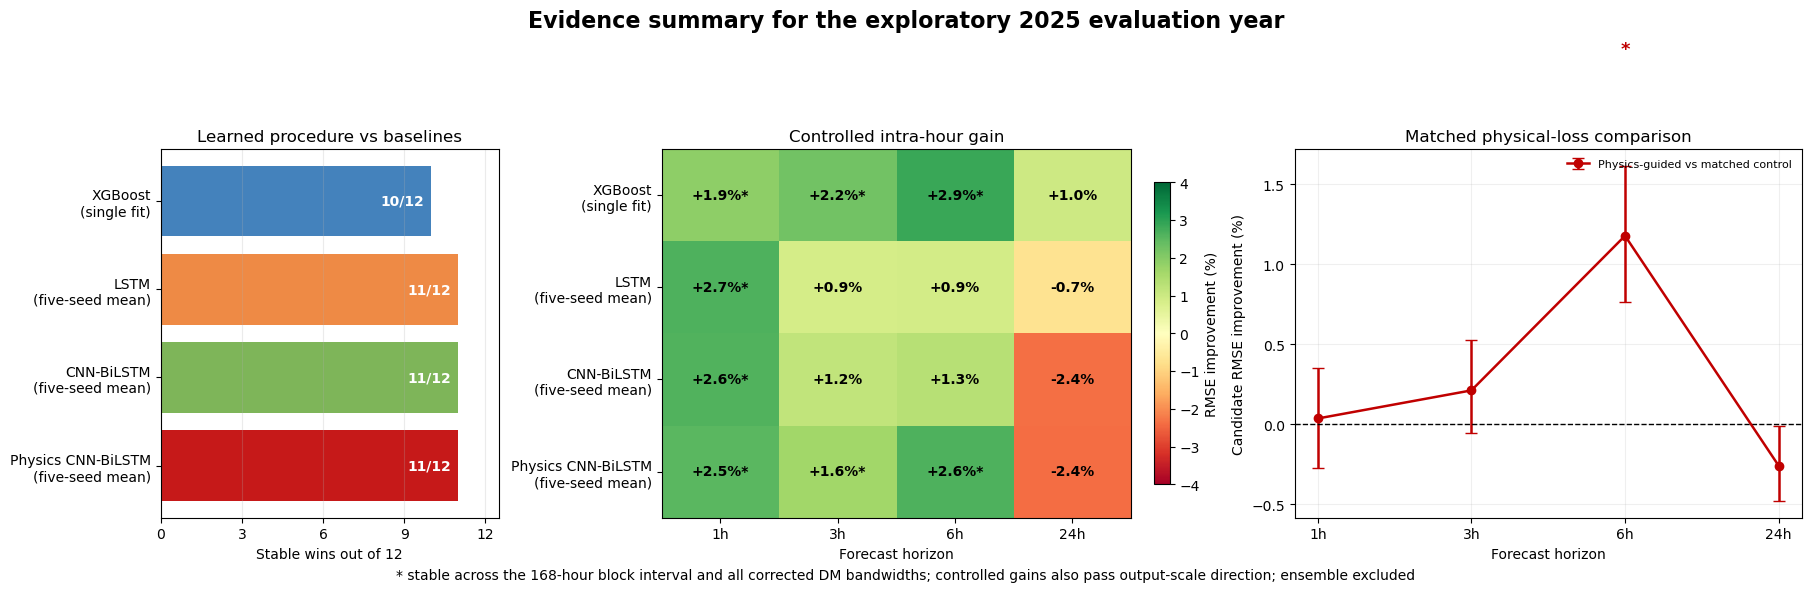

In [29]:
# Use short display labels while retaining full model names in the tables.
short_name = {"XGBoost": "XGBoost\n(single fit)",
              "LSTM": "LSTM\n(five-seed mean)",
              "CNN-BiLSTM": "CNN-BiLSTM\n(five-seed mean)",
              "Physics-guided CNN-BiLSTM":
                  "Physics CNN-BiLSTM\n(five-seed mean)"}

# Count stable wins across three baselines and four forecast horizons.
baseline_counts = (baseline_improvement.loc[
    baseline_improvement.model.isin(learned)]
    .groupby("model").robust_improvement.sum().reindex(learned))

gain_matrix = controlled_summary.pivot(
    index="model", columns="horizon", values="gain_pct").loc[
        learned, HORIZONS]
finding_matrix = controlled_summary.pivot(
    index="model", columns="horizon", values="finding").loc[
        learned, HORIZONS]

# Highlight the matched pair; the full six-pair family appears above.
pair_styles = [("CNN-BiLSTM", "Physics-guided CNN-BiLSTM",
                "Physics-guided vs matched control", "#C00000", 0.00)]

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.6), constrained_layout=True,
    gridspec_kw={"width_ratios": [0.9, 1.25, 1.35]})

# Panel A: number of model-baseline comparisons passing every check.
colours = [evaluation_colours[name] for name in learned]
y = np.arange(len(learned))
axes[0].barh(y, baseline_counts, color=colours, alpha=0.9)
for row, value in enumerate(baseline_counts):
    axes[0].text(value-0.25, row, f"{int(value)}/12", ha="right",
                 va="center", color="white", fontweight="bold")
axes[0].set(yticks=y, yticklabels=[short_name[name] for name in learned],
            xlim=(0, 12.5), xticks=[0, 3, 6, 9, 12],
            xlabel="Stable wins out of 12",
            title="Learned procedure vs baselines")
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=0.25)
axes[0].grid(axis="y", visible=False)

# Panel B: effect size plus the final evidence classification.
limit = max(4, np.nanmax(np.abs(gain_matrix.to_numpy())))
image = axes[1].imshow(gain_matrix, cmap="RdYlGn", vmin=-limit,
                       vmax=limit, aspect="auto")
for row, column in np.ndindex(gain_matrix.shape):
    value = gain_matrix.iloc[row, column]
    stable = finding_matrix.iloc[row, column].startswith("robust")
    axes[1].text(column, row, f"{value:+.1f}%{'*' if stable else ''}",
                 ha="center", va="center", fontweight="bold")
axes[1].set(xticks=range(len(HORIZONS)),
            xticklabels=[f"{h}h" for h in HORIZONS],
            yticks=range(len(learned)),
            yticklabels=[short_name[name] for name in learned],
            xlabel="Forecast horizon",
            title="Controlled intra-hour gain")
axes[1].grid(False)
fig.colorbar(image, ax=axes[1], shrink=0.82,
             label="RMSE improvement (%)")

# Panel C: positive values favour the named candidate over its reference.
x = np.arange(len(HORIZONS))
for reference_model, candidate_model, label, colour, offset in pair_styles:
    values = pairwise_results.loc[
        pairwise_results.reference.eq(reference_model) &
        pairwise_results.candidate.eq(candidate_model)]
    values = values.set_index("horizon").loc[HORIZONS]
    gain = values.candidate_gain_pct.to_numpy()
    lower = gain-values.CI_low.to_numpy()
    upper = values.CI_high.to_numpy()-gain
    axes[2].errorbar(x+offset, gain, yerr=[lower, upper], color=colour,
                     linewidth=1.8, capsize=4, marker="o", markersize=6,
                     label=label)
    for column, row in enumerate(values.itertuples()):
        if row.robust_winner != "No robust difference":
            axes[2].text(column+offset, row.CI_high+0.7, "*", ha="center",
                         color=colour, fontsize=13, fontweight="bold")
axes[2].axhline(0, color="black", linewidth=1, linestyle="--")
axes[2].set(xticks=x, xticklabels=[f"{h}h" for h in HORIZONS],
            xlabel="Forecast horizon",
            ylabel="Candidate RMSE improvement (%)",
            title="Matched physical-loss comparison")
axes[2].legend(loc="upper right", frameon=False, fontsize=8)

fig.suptitle("Evidence summary for the exploratory 2025 evaluation year",
             fontsize=16, fontweight="bold")
fig.text(0.5, -0.025,
         "* stable across the 168-hour block interval and all corrected DM bandwidths; controlled gains also pass output-scale direction; ensemble excluded",
         ha="center", fontsize=10)
fig.savefig(FIGURES/"evidence_summary.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

## 12. Findings and reproducibility
Answer the research question first from the controlled `weather_history` versus `combined` comparison across all four learned procedures. Use the `weather` versus `weather_intra` contrast as complementary evidence about the same inputs when ordinary generation history is absent. A claimed intra-hour contribution should have a meaningful point gain, a moving-block interval that excludes zero, consistent Diebold-Mariano results, and no reversal in the output-scale sensitivity. Weather-regime results can then show where the controlled pattern is concentrated.

Model performance is a separate question. Combined-input RMSE, persistence skill and paired gains establish whether a learned procedure outperforms the three implemented classical baselines. They do not establish that machine learning universally outperforms classical forecasting. Pairwise tests among learned procedures are secondary.

All learned procedures use the same 2 x 2 feature design. XGBoost settings are selected by a feature-set-neutral validation objective and then held fixed across the four arms. The matched CNN-BiLSTM pair isolates the predictive effect of the tested physical loss penalties, but comparisons involving the LSTM or XGBoost remain procedure-level. Neural forecasts are five-seed means, whereas XGBoost is a single fit. Exclusion of ambiguous duplicate scenarios, changing output scale, equal-weight spatial weather averaging, reanalysis latency and repeated inspection of 2025 further narrow the claims. Feature comparisons estimate predictive associations, not causal effects of an input variable.

For a reportable execution, restart the kernel and run every cell in order. The final profile rejects a settings-cell execution count other than 1. The saved run summary records whether the host is Apple Silicon using MPS or a CUDA/ROCm system, together with the OS, conda environment, executable and package versions.

In [30]:
# Finish with report-ready rankings and the exact run configuration.
for h in HORIZONS:
    candidates = results.loc[results.horizon.eq(h) & results.model.isin(models)]
    best = candidates.sort_values("RMSE_MW").iloc[0]
    print(f"{h:2}h: {best['model']} with {best['feature_set']} inputs — "
          f"RMSE {best.RMSE_MW:.2f} MW")
print("\nFactorial feature gains across learned procedures:")
display(comparison.loc[learned, ["history_gain_pct",
                                "intra_gain_without_history_pct",
                                "controlled_intra_gain_pct"]].round(2))
print("Intra-hour gain without hourly history across learned procedures:")
display(comparison.loc[learned, "intra_gain_without_history_pct"].unstack(
    "horizon").round(2))
print("Controlled intra-hour gain across learned procedures:")
display(comparison["controlled_intra_gain_pct"].unstack("horizon").round(2))
print("Duplicate-timestamp audit (legacy AEMO export):")
display(duplicate_audit)
print(f"Run provenance: clean-kernel start verified={CLEAN_KERNEL_START}; "
      f"first code-cell execution count={FIRST_EXECUTION_COUNT}")
print(f"Host: {HOST_HARDWARE} ({MACHINE}) | OS: {platform.platform()} | "
      f"accelerator: {ACCELERATOR}")
print(f"Environment: {ENVIRONMENT} | executable: {sys.executable}")
print(f"Run started (UTC): {RUN_STARTED_UTC} | finished (UTC): "
      f"{pd.Timestamp.now(tz='UTC').isoformat()}")
print(f"Python {platform.python_version()} | torch {torch.__version__} | "
      f"XGBoost {xgb.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"Profile: {RUN_PROFILE}; device: {DEVICE}; seeds: {SEEDS}; window: {WINDOW}; "
      f"epochs: {EPOCHS}; patience: {PATIENCE}; batch: {BATCH}; "
      f"LR: {LR}; trials per horizon: {TRIALS}")

 1h: LSTM with combined inputs — RMSE 155.25 MW
 3h: Physics-guided CNN-BiLSTM with combined inputs — RMSE 300.28 MW
 6h: Physics-guided CNN-BiLSTM with combined inputs — RMSE 369.17 MW
24h: CNN-BiLSTM with weather_history inputs — RMSE 390.54 MW

Factorial feature gains across learned procedures:


feature_set                        history_gain_pct  \
model                     horizon                     
XGBoost                   1                   67.46   
                          3                   51.68   
                          6                   42.24   
                          24                  41.03   
LSTM                      1                   77.07   
                          3                   55.82   
                          6                   45.58   
                          24                  42.98   
CNN-BiLSTM                1                   76.33   
                          3                   55.70   
                          6                   45.15   
                          24                  44.88   
Physics-guided CNN-BiLSTM 1                   76.44   
                          3                   55.63   
                          6                   45.30   
                          24                  44.46   

feature_set                        intra_gain_without_history_pct  \
model                     horizon                                   
XGBoost                   1                                  4.50   
                          3                                  2.95   
                          6                                  2.18   
                          24                                 1.26   
LSTM                      1                                 11.46   
                          3                                  8.07   
                          6                                  6.06   
                          24                                 7.97   
CNN-BiLSTM                1                                  8.72   
                          3                                  6.52   
                          6                                  5.61   
                          24                                 8.06   
Physics-guided CNN-BiLSTM 1                                 10.17   
                          3                                  7.59   
                          6                                  6.09   
                          24                                 7.43   

feature_set                        controlled_intra_gain_pct  
model                     horizon                             
XGBoost                   1                             1.90  
                          3                             2.23  
                          6                             2.86  
                          24                            0.98  
LSTM                      1                             2.65  
                          3                             0.85  
                          6                             0.89  
                          24                           -0.70  
CNN-BiLSTM                1                             2.60  
                          3                             1.18  
                          6                             1.33  
                          24                           -2.37  
Physics-guided CNN-BiLSTM 1                             2.52  
                          3                             1.63  
                          6                             2.64  
                          24                           -2.38

Intra-hour gain without hourly history across learned procedures:


horizon,1,3,6,24
model,,,,
XGBoost,4.50,2.95,2.18,1.26
LSTM,11.46,8.07,6.06,7.97
CNN-BiLSTM,8.72,6.52,5.61,8.06
Physics-guided CNN-BiLSTM,10.17,7.59,6.09,7.43


Controlled intra-hour gain across learned procedures:


horizon,1,3,6,24
model,,,,
CNN-BiLSTM,2.60,1.18,1.33,-2.37
Ensemble,2.91,0.93,2.04,-1.42
LSTM,2.65,0.85,0.89,-0.70
Physics-guided CNN-BiLSTM,2.52,1.63,2.64,-2.38
XGBoost,1.90,2.23,2.86,0.98


Duplicate-timestamp audit (legacy AEMO export):


,duplicate_timestamp_groups,identical_duplicate_groups_collapsed,conflicting_timestamp_groups_dropped,affected_hourly_bins_excluded
0,3532,2619,913,120


Run provenance: clean-kernel start verified=True; first code-cell execution count=1
Host: Apple Silicon (arm64) | OS: macOS-26.6.2-arm64-arm-64bit | accelerator: Apple Silicon MPS
Environment: spunky | executable: /opt/miniconda3/envs/spunky/bin/python
Run started (UTC): 2026-09-14T01:47:44.297506+00:00 | finished (UTC): 2026-09-14T02:38:01.910178+00:00
Python 3.12.12 | torch 2.5.1 | XGBoost 3.0.1 | pandas 2.3.3 | numpy 2.1.3
Profile: final; device: mps; seeds: [42, 123, 456, 789, 1024]; window: 24; epochs: 100; patience: 20; batch: 512; LR: 0.001; trials per horizon: 30
